## New X Services: Service Data Analysis and Spare-Parts Demand Forecasting

- Client: NewX Services
- Category: Forecasting Spare-Parts Inventory
- Domain: Automotive Service and Spare-Parts Inventory
- Forecasting Target: Weekly number of billed stocked-item lines (parts and fluids)
- Forecast Horizon: 1 Week Ahead (rolling one-step forecasts)
- Evaluation Metrics: MAE, RMSE, WAPE and sMAPE

### Business Case and Project Goal

Service centres spend a large share of their budget on spare-parts inventory, yet spare-part availability is still a recurring problem. Matching stock to market demand is difficult.

**Project goal:** To build a predictive model for inventory forecasting so that a service centre can move towards just-in-time (JIT) stocking.

### Python Environment Verification

In [ ]:
import sys
print(sys.version)

3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]


### Library and Version Verification

In [2]:
import importlib

required_libraries = [
    "pandas", "numpy", "matplotlib", "sklearn",
    "statsmodels", "sqlalchemy", "pymysql"
]

missing_libraries = []

for library_name in required_libraries:
    try:
        library = importlib.import_module(library_name)
        print(f"{library_name}: {library.__version__}")
    except ImportError:
        missing_libraries.append(library_name)
        print(f"{library_name}: NOT INSTALLED")

if missing_libraries:
    print("\nMissing libraries:", missing_libraries)
    print("Install them with the pip command shown above, then restart the kernel.")
else:
    print("\nAll required libraries are installed.")

pandas: 3.0.3
numpy: 2.4.6
matplotlib: 3.11.0
sklearn: 1.9.0
statsmodels: 0.15.0
sqlalchemy: 2.1.6
pymysql: 2.2.8

All required libraries are installed.


### Importing Libraries and Project Configuration

In [ ]:
import os
import re
import getpass
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

for folder in (RAW_DIR, PROCESSED_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DB_SCHEMA = "project_service_data"
DB_TABLE = "service_data"
DB_HOST = os.getenv("SERVICE_DB_HOST", "18.136.157.135")
DB_PORT = int(os.getenv("SERVICE_DB_PORT", "3306"))
DB_USER = os.getenv("SERVICE_DB_USER", "dm_usdata_sql")

RAW_SNAPSHOT_PATH = RAW_DIR / "service_data_raw.pkl"
REFRESH_FROM_DATABASE = False

print("Project folder:", PROJECT_DIR)
print("Raw snapshot  :", RAW_SNAPSHOT_PATH)

Project folder: c:\Users\meham\Downloads
Raw snapshot  : c:\Users\meham\Downloads\data\raw\service_data_raw.pkl


### Loading the Service Dataset

In [ ]:

import os
import getpass
import pandas as pd

from pathlib import Path
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# 1. DATABASE CONFIGURATION

DB_USER = "dm_usdata_sql"
DB_HOST = "projects.datamites.com"
DB_PORT = 3306
DB_SCHEMA = "project_service_data"
DB_TABLE = "service_data"


# 2. SNAPSHOT CONFIGURATION

RAW_SNAPSHOT_PATH = Path("service_data_snapshot.pkl")

REFRESH_FROM_DATABASE = True


# 3. DATABASE CONNECTION

def get_engine():

    password = (
        os.getenv("SERVICE_DB_PASSWORD")
        or getpass.getpass("Enter DataMites MySQL password: ")
    )

    db_url = URL.create(
        drivername="mysql+pymysql",
        username=DB_USER,
        password=password,
        host=DB_HOST,
        port=DB_PORT,
        database=DB_SCHEMA
    )

    return create_engine(
        db_url,
        pool_pre_ping=True,
        connect_args={"connect_timeout": 15}
    )


# 4. LOAD DATASET

engine = None

if RAW_SNAPSHOT_PATH.exists() and not REFRESH_FROM_DATABASE:

    df_raw = pd.read_pickle(RAW_SNAPSHOT_PATH)

    print("Loaded local snapshot:", RAW_SNAPSHOT_PATH)

else:

    try:

        engine = get_engine()

        with engine.connect() as conn:

            print("Database connection successful!")

            database_name = conn.execute(
                text("SELECT DATABASE()")
            ).scalar()

            print("Connected Database:", database_name)

            # to check available records
            record_count = conn.execute(
                text(f"SELECT COUNT(*) FROM `{DB_TABLE}`")
            ).scalar()

            print("Available Records:", record_count)

            # To load original project dataset
            query = text(
                f"SELECT * FROM `{DB_TABLE}`"
            )

            df_raw = pd.read_sql(query, conn)

        # To save local snapshot
        df_raw.to_pickle(RAW_SNAPSHOT_PATH)

        print("Snapshot saved:", RAW_SNAPSHOT_PATH)

    except Exception as error:

        raise RuntimeError(
            f"DataMites database loading failed: {error}"
        ) from error

    finally:

        if engine is not None:
            engine.dispose()

# 5. DATASET VALIDATION

print("DATAMITES DATASET LOADED SUCCESSFULLY")

print("Dataset Shape:", df_raw.shape)

print("\nColumn Names:")
print(df_raw.columns.tolist())

print("\nDataset Information:")
df_raw.info()

print("\nFirst 5 Records:")
display(df_raw.head())


## Task-1: Service Data Analysis

### Database Structure Inspection

In [ ]:
if engine is not None:
    with engine.connect() as conn:
        print("All databases visible to this user:")
        print(pd.read_sql(text("SHOW DATABASES"), conn))

        print("\nTables in", DB_SCHEMA + ":")
        print(pd.read_sql(text(f"SHOW TABLES FROM {DB_SCHEMA}"), conn))

        schema = pd.read_sql(text(f"DESCRIBE {DB_SCHEMA}.{DB_TABLE}"), conn)

        row_count = pd.read_sql(
            text(f"SELECT COUNT(*) AS total_rows FROM {DB_SCHEMA}.{DB_TABLE}"), conn
        )

    print("\nTable schema:")
    display(schema)

    print("Row count in the database:")
    display(row_count)

else:
    print("Database inspection skipped: the data was loaded from the local snapshot.")

All databases visible to this user:
               Database
0    information_schema
1  project_service_data

Tables in project_service_data:
  Tables_in_project_service_data
0                   service_data

Table schema:


,Field,Type,Null,Key,Default,Extra
0,invoice_date,varchar(50),YES,,None,
1,job_card_date,varchar(50),YES,,None,
2,business_partner_name,varchar(80),YES,,None,
3,vehicle_no,varchar(50),YES,,None,
4,vehicle_model,varchar(80),YES,,None,
5,current_km_reading,varchar(50),YES,,None,
6,invoice_line_text,varchar(120),YES,,None,


Row count in the database:


,total_rows
0,28482


### Initial Dataset Inspection

In [ ]:
df_raw.head(10)

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL
5,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CHAIN LUBRICATION
6,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,4 WAY SWITCH
7,31-05-17,31-05-17,pattXXXXXXXXXX,KA53EMXXXX,BAJAJ PLATINA,3717,ENGINE OIL
8,31-05-17,31-05-17,pattXXXXXXXXXX,KA53EMXXXX,BAJAJ PLATINA,3717,3M OIL
9,31-05-17,31-05-17,pattXXXXXXXXXX,KA53EMXXXX,BAJAJ PLATINA,3717,CHAIN LUBRICATION


In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 28482 entries, 0 to 28481
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   invoice_date           28482 non-null  str  
 1   job_card_date          28482 non-null  str  
 2   business_partner_name  28482 non-null  str  
 3   vehicle_no             28482 non-null  str  
 4   vehicle_model          28482 non-null  str  
 5   current_km_reading     28482 non-null  str  
 6   invoice_line_text      28476 non-null  str  
dtypes: str(7)
memory usage: 1.5 MB


In [ ]:
df_raw.isna().sum()

invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        6
dtype: int64

In [ ]:
df_raw.duplicated().sum()

np.int64(383)

In [ ]:
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

Number of rows: 28482
Number of columns: 7


In [ ]:
# Empty or whitespace-only text is not detected by isna(), so check it separately
blank_counts = df_raw.apply(lambda col: col.astype(str).str.strip().eq("")).sum()

print("Blank (empty text) values per column:")
print(blank_counts)

Blank (empty text) values per column:
invoice_date              0
job_card_date             0
business_partner_name     0
vehicle_no                0
vehicle_model             0
current_km_reading        0
invoice_line_text        28
dtype: int64


### Duplicate Row Investigation

In [ ]:
dup_mask = df_raw.duplicated(keep=False)
dups = df_raw[dup_mask]

print("Rows involved in duplicate groups:", len(dups))
print("Extra copies (what duplicated() counted):", df_raw.duplicated().sum())

group_sizes = dups.groupby(list(df_raw.columns), dropna=False).size()

print("\nNumber of groups by copy count:")
print(group_sizes.value_counts().sort_index())

print("\nTop 15 items among duplicate rows:")
print(dups["invoice_line_text"].value_counts().head(15))

dups.sort_values(["vehicle_no", "invoice_date"]).head(20)

Rows involved in duplicate groups: 720
Extra copies (what duplicated() counted): 383

Number of groups by copy count:
2     316
3      11
4       3
5       6
13      1
Name: count, dtype: int64

Top 15 items among duplicate rows:
invoice_line_text
BRAKE SHOE           204
DISC PAD              89
CHAIN LUBRICATION     44
ENGINE OIL            40
AIR FILTER            31
TYRE                  24
CONSUMABLES           22
3M OIL                22
GENERAL SERVICE       20
                      17
OIL FILTER            14
SPARK PLUG            14
POLISH                14
DISC OIL              12
SWITCH                10
Name: count, dtype: int64


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
22494,08-10-18,08-10-18,SIDDXXXXXXXXXX,AP02BLXXXX,BAJAJ PULSAR 150,12627,BRAKE SHOE
22498,08-10-18,08-10-18,SIDDXXXXXXXXXX,AP02BLXXXX,BAJAJ PULSAR 150,12627,BRAKE SHOE
20254,05-09-18,05-09-18,upenXXXXXXXXXX,AP02BSXXXX,BAJAJ PULSAR 220,10960,HEAD LIGHT HOLDER
20256,05-09-18,05-09-18,upenXXXXXXXXXX,AP02BSXXXX,BAJAJ PULSAR 220,10960,HEAD LIGHT HOLDER
4913,04-10-17,04-10-17,bharXXXXXXXXXX,AP04L1XXXX,BAJAJ PULSAR 150,97450,DISC PLATE
4918,04-10-17,04-10-17,bharXXXXXXXXXX,AP04L1XXXX,BAJAJ PULSAR 150,97450,DISC PLATE
2636,04-08-17,04-08-17,santXXXXXXXXXX,AP16CWXXXX,BAJAJ DISCOVER 150,17377,AIR FILTER
2637,04-08-17,04-08-17,santXXXXXXXXXX,AP16CWXXXX,BAJAJ DISCOVER 150,17377,AIR FILTER
3895,08-09-17,08-09-17,raviXXXXXXXXXX,AP28DSXXXX,BAJAJ PULSAR 150,35772,CLUTCH ASSEMBLY
3899,08-09-17,08-09-17,raviXXXXXXXXXX,AP28DSXXXX,BAJAJ PULSAR 150,35772,CLUTCH ASSEMBLY


### Missing and Blank Item Names

In [ ]:
item_text = df_raw["invoice_line_text"]
empty_item_mask = item_text.isna() | item_text.str.strip().eq("")

print("Rows with missing or blank item text:", empty_item_mask.sum())

df_raw[empty_item_mask].head(15)

Rows with missing or blank item text: 34


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
545,16-06-17,13-06-17,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,2615,
632,15-06-17,14-06-17,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,NaN
635,15-06-17,14-06-17,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,NaN
661,15-06-17,14-06-17,kailXXXXXXXXXX,KA01HNXXXX,BAJAJ PULSAR 150,8679,NaN
769,16-06-17,16-06-17,hariXXXXXXXXXX,KA53ESXXXX,BAJAJ AVENGER STREET,457,NaN
2139,21-07-17,21-07-17,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,12457,
2579,01-08-17,01-08-17,hariXXXXXXXXXX,KA53EQXXXX,BAJAJ PULSAR 150,9677,NaN
2613,03-08-17,03-08-17,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,251447,NaN
10809,27-02-18,27-02-18,PRAVXXXXXXXXXX,KA04JBXXXX,BAJAJ PULSAR 150,24447,
10810,27-02-18,27-02-18,PRAVXXXXXXXXXX,KA04JBXXXX,BAJAJ PULSAR 150,24447,


### Text Standardization and Data-Quality Flags

In [ ]:
df = df_raw.copy()

df["is_repeat_row"] = df_raw.duplicated()   
df["item_missing"] = (
    df_raw["invoice_line_text"].isna()
    | df_raw["invoice_line_text"].str.strip().eq("")
)

text_cols = ["business_partner_name", "vehicle_no", "vehicle_model", "invoice_line_text"]
unique_before = {col: df[col].nunique() for col in text_cols}

for col in text_cols:
    df[col] = df[col].str.strip().str.upper()                 
    df[col] = df[col].str.replace(r"\s+", " ", regex=True)    

df["invoice_line_text"] = df["invoice_line_text"].replace("", np.nan)

print("TEXT STANDARDIZATION RESULTS")
print("=" * 60)

for col in text_cols:
    print(f"{col}: unique values {unique_before[col]} -> {df[col].nunique()}")

print("\nFlagged repeat rows:", df["is_repeat_row"].sum())
print("Flagged missing items:", df["item_missing"].sum())
print("Exact duplicates after text cleaning:", df[df_raw.columns].duplicated().sum())

TEXT STANDARDIZATION RESULTS
business_partner_name: unique values 1010 -> 801
vehicle_no: unique values 846 -> 846
vehicle_model: unique values 28 -> 28
invoice_line_text: unique values 503 -> 493

Flagged repeat rows: 383
Flagged missing items: 34
Exact duplicates after text cleaning: 390


### Data Type Conversion

In [ ]:
for col in ["invoice_date", "job_card_date"]:
    df[col] = pd.to_datetime(df[col], format="%d-%m-%y", errors="coerce")

df["current_km_reading"] = pd.to_numeric(df["current_km_reading"], errors="coerce")

print("Rows that failed to convert (became missing):")
print(df[["invoice_date", "job_card_date", "current_km_reading"]].isna().sum())

print("\nInvoice date range:", df["invoice_date"].min(), "to", df["invoice_date"].max())
print("Job card date range:", df["job_card_date"].min(), "to", df["job_card_date"].max())

print("\nKM summary:")
print(df["current_km_reading"].describe())

Rows that failed to convert (became missing):
invoice_date          0
job_card_date         0
current_km_reading    0
dtype: int64

Invoice date range: 2017-05-30 00:00:00 to 2019-01-06 00:00:00
Job card date range: 2017-05-30 00:00:00 to 2019-01-06 00:00:00

KM summary:
count     28482.000000
mean      19348.003827
std       25246.722306
min           0.000000
25%        3988.000000
50%       12420.500000
75%       27905.000000
max      610112.000000
Name: current_km_reading, dtype: float64


### Re-Checking Duplicates After Cleaning

In [ ]:
clean_cols = list(df_raw.columns)   

df["is_repeat_row_raw"] = df["is_repeat_row"]                
df["is_repeat_row"] = df.duplicated(subset=clean_cols)       

new_dups = df["is_repeat_row"] & ~df["is_repeat_row_raw"]

print("Newly flagged after cleaning:", new_dups.sum())
print("Total repeat rows now:", df["is_repeat_row"].sum())

pd.concat(
    [
        df_raw.loc[new_dups, ["business_partner_name", "invoice_line_text"]],
        df.loc[new_dups, ["business_partner_name", "invoice_line_text"]],
    ],
    axis=1,
    keys=["raw", "clean"]
)

Newly flagged after cleaning: 7
Total repeat rows now: 390


raw                                     clean  \
      business_partner_name   invoice_line_text business_partner_name   
12166        SRITXXXXXXXXXX     GENERAL SERVICE        SRITXXXXXXXXXX   
12167        SRITXXXXXXXXXX   CHAIN LUBRICATION        SRITXXXXXXXXXX   
12168        SRITXXXXXXXXXX            DISC OIL        SRITXXXXXXXXXX   
12169        SRITXXXXXXXXXX          ENGINE OIL        SRITXXXXXXXXXX   
12170        SRITXXXXXXXXXX          OIL FILTER        SRITXXXXXXXXXX   
12171        SRITXXXXXXXXXX  AIR FILTER CHECKUP        SRITXXXXXXXXXX   
12172        SRITXXXXXXXXXX          AIR FILTER        SRITXXXXXXXXXX   

                           
        invoice_line_text  
12166     GENERAL SERVICE  
12167   CHAIN LUBRICATION  
12168            DISC OIL  
12169          ENGINE OIL  
12170          OIL FILTER  
12171  AIR FILTER CHECKUP  
12172          AIR FILTER

In [ ]:
keys = df.loc[new_dups, clean_cols].drop_duplicates()
twin_idx = df.reset_index().merge(keys, on=clean_cols)["index"]

df_raw.loc[sorted(twin_idx)].head(30)

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
12116,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,GENERAL SERVICE
12117,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,ENGINE OIL
12118,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,OIL FILTER
12119,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,AIR FILTER CHECKUP
12120,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,CHAIN LUBRICATION
12121,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,DISC OIL
12122,27-03-18,27-03-18,sritXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,AIR FILTER
12166,27-03-18,27-03-18,SRITXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,GENERAL SERVICE
12167,27-03-18,27-03-18,SRITXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,CHAIN LUBRICATION
12168,27-03-18,27-03-18,SRITXXXXXXXXXX,OD02Y6XXXX,BAJAJ PULSAR AS 200,19868,DISC OIL


### Checking Invoice and Job-Card Date Consistency

In [ ]:
df["days_to_invoice"] = (df["invoice_date"] - df["job_card_date"]).dt.days

print(df["days_to_invoice"].describe())

print("\nInvoice BEFORE job card (negative):", (df["days_to_invoice"] < 0).sum())
print("Same day:", (df["days_to_invoice"] == 0).sum())
print("Invoice AFTER job card:", (df["days_to_invoice"] > 0).sum())

gap_counts = df["days_to_invoice"].value_counts().sort_index()

print("\nSmallest gaps:\n", gap_counts.head(8))
print("\nLargest gaps:\n", gap_counts.tail(8))

df["date_order_issue"] = df["days_to_invoice"] < 0

count    28482.000000
mean         0.034653
std          0.439955
min         -1.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         19.000000
Name: days_to_invoice, dtype: float64

Invoice BEFORE job card (negative): 5
Same day: 28066
Invoice AFTER job card: 411

Smallest gaps:
 days_to_invoice
-1         5
 0     28066
 1       233
 2        23
 3        83
 4        16
 5        47
 16        2
Name: count, dtype: int64

Largest gaps:
 days_to_invoice
0     28066
1       233
2        23
3        83
4        16
5        47
16        2
19        7
Name: count, dtype: int64


### Kilometre Reading Outlier Analysis

In [ ]:
km = df["current_km_reading"]

q1, q3 = km.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)

print("Upper fence (IQR rule):", round(upper_fence))
print("KM equal to 0:", (km == 0).sum())
print("KM above fence:", (km > upper_fence).sum())
print("KM >= 100,000:", (km >= 100_000).sum())
print("KM >= 200,000:", (km >= 200_000).sum())

df.loc[
    km.nlargest(10).index,
    ["invoice_date", "vehicle_no", "vehicle_model", "current_km_reading"]
]

Upper fence (IQR rule): 63780
KM equal to 0: 842
KM above fence: 1179
KM >= 100,000: 36
KM >= 200,000: 36


,invoice_date,vehicle_no,vehicle_model,current_km_reading
8428,2017-12-29,MH14CRXXXX,BAJAJ PULSAR LS135,610112
8429,2017-12-29,MH14CRXXXX,BAJAJ PULSAR LS135,610112
8430,2017-12-29,MH14CRXXXX,BAJAJ PULSAR LS135,610112
445,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147
446,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147
447,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147
448,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147
449,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147
450,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147
451,2017-06-13,KA03JCXXXX,BAJAJ PULSAR 150,550147


In [ ]:
zero_km = df[df["current_km_reading"] == 0]

print("Top items when KM = 0:")
print(zero_km["invoice_line_text"].value_counts().head(10))

veh_with_zero = zero_km["vehicle_no"].unique()
positive_other = df[
    df["vehicle_no"].isin(veh_with_zero) & (df["current_km_reading"] > 0)
]

print("\nVehicles with a zero reading:", len(veh_with_zero))
print("...of which also have a positive reading elsewhere:", positive_other["vehicle_no"].nunique())

extreme = df[df["current_km_reading"] >= 200_000]

print("\nRows >= 200,000 km:", len(extreme), "| vehicles:", extreme["vehicle_no"].nunique())

history = (
    df[df["vehicle_no"].isin(extreme["vehicle_no"].unique())]
    .groupby(["vehicle_no", "invoice_date"])["current_km_reading"]
    .agg(km_min="min", km_max="max")
    .reset_index()
)

history.head(30)

Top items when KM = 0:
invoice_line_text
LABOUR               67
ENGINE OIL           61
CHAIN LUBRICATION    44
GENERAL SERVICE      38
SPARK PLUG           20
AIR FILTER           19
CHAIN SPROCKET       18
OIL FILTER           18
WASHING              17
CHAIN OVERHAUL       15
Name: count, dtype: int64

Vehicles with a zero reading: 121
...of which also have a positive reading elsewhere: 80

Rows >= 200,000 km: 36 | vehicles: 6


,vehicle_no,invoice_date,km_min,km_max
0,KA03HVXXXX,2017-06-06,26305,26305
1,KA03HVXXXX,2017-08-10,27203,27203
2,KA03HVXXXX,2017-09-14,34180,34180
3,KA03HVXXXX,2017-11-04,287188,287188
4,KA03HVXXXX,2018-01-22,18043,18043
5,KA03HVXXXX,2018-04-11,33612,33612
6,KA03HVXXXX,2018-05-05,19487,19487
7,KA03HVXXXX,2018-08-27,26157,26157
8,KA03HVXXXX,2018-09-26,16951,16951
9,KA03HVXXXX,2018-11-26,34866,34866


In [ ]:
df["vehicle_model"].value_counts()

vehicle_model
BAJAJ PULSAR 150            8633
BAJAJ AVENGER STREET 220    4212
BAJAJ PULSAR 220            2655
BAJAJ PULSAR 180            2252
BAJAJ PULSAR NS 200         2204
BAJAJ CT 100                1432
BAJAJ DISCOVER 125          1346
BAJAJ AVENGER STREET        1112
BAJAJ PLATINA                844
BAJAJ V150                   686
BAJAJ DISCOVER               679
BAJAJ PULSAR LS135           520
BAJAJ PULSAR AS 200          421
BAJAJ PULSAR NS 160          364
BAJAJ PULSAR RS 200          322
BAJAJ DISCOVER 150           284
BAJAJ AVENGER STREET 180     122
BAJAJ DISCOVER 135           115
BAJAJ V125                    95
BAJAJ V                       54
BAJAJ CALIBER                 40
BAJAJ XCD 125                 27
BAJAJ V15                     23
BAJAJ XCD 135                 13
WAVE                          10
BAJAJ DOMINAR 400 ABS          7
BAJAJ WIND 125                 6
BAJAJ BOXER CT                 4
Name: count, dtype: int64

In [ ]:
df["km_zero"] = df["current_km_reading"] == 0
df["km_extreme"] = df["current_km_reading"] >= 200_000

df["km_clean"] = df["current_km_reading"].mask(df["km_zero"] | df["km_extreme"])

print(df[["km_zero", "km_extreme"]].sum())

print("\nCleaned KM summary:")
print(df["km_clean"].describe())

km_zero       842
km_extreme     36
dtype: int64

Cleaned KM summary:
count    27604.000000
mean     19361.016121
std      19345.433206
min          1.000000
25%       4426.000000
50%      13224.000000
75%      28343.000000
max      99625.000000
Name: km_clean, dtype: float64


## Kilometre Reading Anomalies

- A total of 842 rows have a kilometre reading of zero, and 36 rows (from 6 vehicles) have readings of 200,000 km or more, with a maximum of 610,112 km. The extreme readings belong to vehicles whose other visits show normal readings (for example, vehicles KA03HVXXXX and KA03JCXXXX have most visits between roughly 7,000 and 57,000 km), so they are most likely data-entry errors rather than real mileage.


### Visit-Level Repeat Row Analysis

In [ ]:
visit_cols = ["vehicle_no", "invoice_date", "current_km_reading"]

visit_stats = (
    df.groupby(visit_cols)
    .agg(
        rows_in_visit=("invoice_line_text", "size"),
        repeat_rows=("is_repeat_row", "sum")
    )
    .reset_index()
)

visit_stats["repeat_share"] = visit_stats["repeat_rows"] / visit_stats["rows_in_visit"]

with_repeats = visit_stats[visit_stats["repeat_rows"] > 0]

print("Visits in total:", len(visit_stats))
print("Visits containing repeat rows:", len(with_repeats))

print("\nHow many repeat rows per visit:")
print(with_repeats["repeat_rows"].value_counts().sort_index())

print("\nVisits with 4 or more repeat rows:", (with_repeats["repeat_rows"] >= 4).sum())

print("\nVisits with the most repeat rows:")
print(with_repeats.sort_values("repeat_rows", ascending=False).head(15))

Visits in total: 4155
Visits containing repeat rows: 227

How many repeat rows per visit:
repeat_rows
1     196
2       6
3       3
4       3
5       5
6       2
7       2
8       4
10      2
11      2
12      1
24      1
Name: count, dtype: int64

Visits with 4 or more repeat rows: 22

Visits with the most repeat rows:
      vehicle_no invoice_date  current_km_reading  rows_in_visit  repeat_rows  \
2742  KA53ETXXXX   2018-07-10                5620             30           24   
1045  KA04JBXXXX   2018-02-27               24447             13           12   
1068  KA04JJXXXX   2018-08-11               15595             22           11   
1317  KA41EDXXXX   2018-10-15               36496             24           11   
3343  KA53EXXXXX   2018-06-26                 541             15           10   
3815  KA53Y5XXXX   2018-02-27               23784             23           10   
515   KA03HQXXXX   2018-04-10               18085             16            8   
2185  KA53EQXXXX   2018-12-24 

In [ ]:
def show_visit(vehicle, date, km):
    """Return all invoice lines of one visit, with the repeat flag."""
    mask = (
        (df["vehicle_no"] == vehicle)
        & (df["invoice_date"] == pd.Timestamp(date))
        & (df["current_km_reading"] == km)
    )

    columns = ["business_partner_name", "invoice_line_text", "is_repeat_row"]

    return df.loc[mask, columns].sort_values("invoice_line_text", na_position="last")


example_visits = [
    ("KA53ETXXXX", "2018-07-10", 5620),    # 30 rows, 24 repeats
    ("KA04JBXXXX", "2018-02-27", 24447),   # 13 rows, 12 repeats
    ("KA04JJXXXX", "2018-08-11", 15595),   # 22 rows, 11 repeats
]

for vehicle, date, km_value in example_visits:
    print(f"Visit: {vehicle} | {date} | {km_value} km")
    print(show_visit(vehicle, date, km_value).to_string())
    print()

Visit: KA53ETXXXX | 2018-07-10 | 5620 km
      business_partner_name  invoice_line_text  is_repeat_row
17343        SANTXXXXXXXXXX             3M OIL           True
17322        SANTXXXXXXXXXX             3M OIL          False
17324        SANTXXXXXXXXXX             3M OIL           True
17335        SANTXXXXXXXXXX             3M OIL           True
17330        SANTXXXXXXXXXX             3M OIL           True
17331        SANTXXXXXXXXXX         AIR FILTER           True
17318        SANTXXXXXXXXXX         AIR FILTER          False
17340        SANTXXXXXXXXXX         AIR FILTER           True
17337        SANTXXXXXXXXXX         AIR FILTER           True
17333        SANTXXXXXXXXXX         AIR FILTER           True
17336        SANTXXXXXXXXXX  CHAIN LUBRICATION           True
17317        SANTXXXXXXXXXX  CHAIN LUBRICATION          False
17321        SANTXXXXXXXXXX  CHAIN LUBRICATION           True
17320        SANTXXXXXXXXXX  CHAIN LUBRICATION           True
17326        SANTXXXXXXXXXX  

In [ ]:
large_repeat_visits = with_repeats[with_repeats["repeat_rows"] >= 4].sort_values("repeat_share")

print(
    large_repeat_visits[
        ["vehicle_no", "invoice_date", "rows_in_visit", "repeat_rows", "repeat_share"]
    ].to_string()
)

      vehicle_no invoice_date  rows_in_visit  repeat_rows  repeat_share
4096  TN70E6XXXX   2018-09-24             12            5      0.416667
3815  KA53Y5XXXX   2018-02-27             23           10      0.434783
670   KA03JDXXXX   2017-11-30              9            4      0.444444
2949  KA53EVXXXX   2017-12-01              9            4      0.444444
3555  KA53EYXXXX   2018-10-17              9            4      0.444444
3384  KA53EXXXXX   2018-08-03             11            5      0.454545
1317  KA41EDXXXX   2018-10-15             24           11      0.458333
3479  KA53EXXXXX   2018-11-27             17            8      0.470588
2560  KA53ESXXXX   2018-12-10             12            6      0.500000
2185  KA53EQXXXX   2018-12-24             16            8      0.500000
1068  KA04JJXXXX   2018-08-11             22           11      0.500000
1901  KA53EPXXXX   2017-11-16             14            7      0.500000
3611  KA53EYXXXX   2018-11-23             12            6      0

### New-Registration Vehicles

In [ ]:
newreg = df["vehicle_no"].str.startswith("NEWREG")

print("Rows with vehicle_no starting NEWREG:", newreg.sum())
print("KM = 0 among NEWREG rows:", (newreg & df["km_zero"]).sum())
print("KM = 0 among all other rows:", (~newreg & df["km_zero"]).sum())

print("\nSmallest non-zero KM values (below 100):")
print(df.loc[df["km_clean"] < 100, "km_clean"].value_counts().sort_index().head(10))

Rows with vehicle_no starting NEWREG: 25
KM = 0 among NEWREG rows: 14
KM = 0 among all other rows: 828

Smallest non-zero KM values (below 100):
km_clean
1.0     16
2.0     44
3.0     19
4.0     21
5.0      6
50.0     5
62.0     3
71.0     4
Name: count, dtype: int64


### Creating the Demand Analysis Dataset

In [ ]:
visit_cols = ["vehicle_no", "invoice_date", "current_km_reading"]
df["visit_repeat_rows"] = df.groupby(visit_cols)["is_repeat_row"].transform("sum")

df["is_block_repeat"] = df["is_repeat_row"] & (df["visit_repeat_rows"] >= 4)

df["exclude_from_demand"] = df["is_block_repeat"] | df["item_missing"]

df["is_newreg"] = df["vehicle_no"].str.startswith("NEWREG")

df_demand = df[~df["exclude_from_demand"]].copy()

print("DEMAND DATASET CREATION")
print("=" * 60)

print("Block repeat rows:", df["is_block_repeat"].sum())
print("Repeat rows kept:", (df["is_repeat_row"] & ~df["is_block_repeat"]).sum())
print("Missing-item rows:", df["item_missing"].sum())
print("Excluded in total:", df["exclude_from_demand"].sum())

print("\ndf shape:", df.shape, "| df_demand shape:", df_demand.shape)
print("Unique items in df_demand:", df_demand["invoice_line_text"].nunique())

df.to_pickle(PROCESSED_DIR / "df_stage4_clean.pkl")

DEMAND DATASET CREATION
Block repeat rows: 173
Repeat rows kept: 217
Missing-item rows: 34
Excluded in total: 195

df shape: (28482, 19) | df_demand shape: (28287, 19)
Unique items in df_demand: 493


### Demand Dataset Summary

In [ ]:
summary = pd.Series({
    "Rows": len(df_demand),
    "Unique masked vehicle numbers": df_demand["vehicle_no"].nunique(),
    "Unique vehicle models": df_demand["vehicle_model"].nunique(),
    "Unique business partners (masked)": df_demand["business_partner_name"].nunique(),
    "Unique invoice line items": df_demand["invoice_line_text"].nunique(),
    "First invoice date": df_demand["invoice_date"].min().date(),
    "Last invoice date": df_demand["invoice_date"].max().date(),
    "Calendar days in range": (df_demand["invoice_date"].max() - df_demand["invoice_date"].min()).days + 1,
    "Days with at least one invoice": df_demand["invoice_date"].nunique(),
})

summary.to_frame("value")

,value
Rows,28287
Unique masked vehicle numbers,846
Unique vehicle models,28
Unique business partners (masked),801
Unique invoice line items,493
First invoice date,2017-05-30
Last invoice date,2019-01-06
Calendar days in range,587
Days with at least one invoice,555


### Invoice Line Item Frequency Analysis

In [ ]:
item_counts = df_demand["invoice_line_text"].value_counts()

print("Top 40 items by number of rows:")
print(item_counts.head(40))

total_rows = item_counts.sum()

print("\nCUMULATIVE SHARE OF ROWS")
print("=" * 40)

for top_n in [5, 10, 20, 50, 100]:
    share = item_counts.head(top_n).sum() / total_rows
    print(f"Top {top_n} items = {share:.1%} of all rows")

bands = pd.cut(
    item_counts,
    bins=[0, 4, 9, 49, 199, np.inf],
    labels=["1-4 rows", "5-9 rows", "10-49 rows", "50-199 rows", "200+ rows"]
)

print("\nHow many items fall in each frequency band:")
print(bands.value_counts().sort_index())

Top 40 items by number of rows:
invoice_line_text
ENGINE OIL             3780
CHAIN LUBRICATION      3420
GENERAL SERVICE        2131
AIR FILTER             1700
3M OIL                 1619
CONSUMABLES            1584
POLISH                 1236
DISC OIL                986
BRAKE SHOE              957
OIL FILTER              813
DISC PAD                572
WHEEL RUBBER            520
AIR FILTER CHECKUP      466
SPARK PLUG              418
CHAIN SPROCKET          394
SPROCKET RUBBER         344
CLUTCH CABLE            341
SPROCKET BEARING        312
CHAIN OVERHAUL          283
CLUTCH ASSEMBLY         211
CLUTCH COVER GASKET     188
CLUTCH OVERHUAL         162
TANK COVER              134
LABOUR                  131
SEAT COVER              118
INDICATOR               110
DISC PUMP KIT           104
DRUM BOLT               102
TAIL LAMP BULB          101
FOOT REST                99
CLUTCH LEVER             98
FORK OIL                 95
MIRROR                   91
BATTERY                  8

In [ ]:
rare_items = item_counts[item_counts <= 4].index.tolist()

print(len(rare_items), "rare items")
print(", ".join(sorted(rare_items)))

277 rare items
10 SIZE NUT, 12 SIZE BOLT, 4 WAY SWITCH, 6004 BEARING, 6202 BEARING, 6303 BEARING, 8 SIZE BOLT, ADD ON FEES, AXLE, BATTERY CLIP, BATTERY TARMINAL, BC UNIT, BEARING, BEARING SET, BEARING WIELDING, BEDDING BOLT, BODY, BODY COVER, BOLT REMOVAL, BOLT WIELDING, BORE, BORE GASKET, BOTTLE COIL, BRAKE BUSH KIT, BRAKE LIGHT SPRING, BRAKE PEDAL RUBBER, BRAKE ROD, BRAKE ROD SPRING, BRAKE RUBBER, BRAKE SWITCH, BULB HOLDER, CABLE LOCK, CAHIN PAD SCREW, CALIPER RUBBER KIT, CAM SHAFT SPRING, CARBURETOR, CARBURETOR CLEANING, CARBURETOR PLATE, CARBURETOR SPRING, CASE BEARING, CASE WELDING, CENTER STAND, CENTER STAND SPRING, CHAIN LINK LOCK, CHAIN PAD, CHOKE CABLE, CHOKE SENSOR, CLUTCH ADJUSTMENT, CLUTCH CAM SWITCH, CLUTCH COVER PACKING, CLUTCH OUTLET PIPE, CLUTCH REPALCEMENT, CLUTCH ROLLERS, CLUTCH SHOE, CLUTCH SPRING KIT, COIL, COIL LABOUR, COIL OVERHUAL, COIL START, CONE SET OVERHUAL, COOLANT OIL HOSE PIPE, COOLANT OIL SENSOR, COOLANT OIL TANK, CRASH GASKET, CRASH GUARD BOLT, DISC ASSE

In [ ]:
print(item_counts.iloc[40:100].to_string())

invoice_line_text
FORK OVERHUAL                  72
COOLANT OIL                    70
BRAKE LIGHT SWITCH             67
VALVE KIT                      66
FORK CONE SET                  65
GEAR SHAFT                     64
VALVE GUIDE                    63
VALVE GRAINDING                63
DISK PAD                       63
FORK OIL SEAL                  58
CALIPER ASSEMBLY               57
HEAD REST                      56
PACKING KIT                    56
BORE KIT                       56
TYRE                           53
MASTER CYLENDER                53
LOADING GEAR                   52
WASHING                        52
ACCELATOR CABLE                51
CRANK SHAFT                    50
ENGINE BEARING                 50
SWITCH                         50
FORK BEND                      49
CRANK RESET                    49
ENGINE LABOUR                  49
ENGINE GUARD                   46
SPEEDOMETER CABLE              46
COIL CHECK                     45
HALF ACCELERATOR              

### Correcting Misspelled Item Names

In [ ]:
typo_map = {
    "OVERHUAL": "OVERHAUL", "TIMMING": "TIMING", "WIELDING": "WELDING",
    "LABOR": "LABOUR", "CYLENDER": "CYLINDER", "ACCELATOR": "ACCELERATOR",
    "ACCELETOR": "ACCELERATOR", "MUDGAURD": "MUDGUARD", "SPPEDOMETER": "SPEEDOMETER",
    "DISK": "DISC", "VISIOR": "VISOR", "ASSEBLY": "ASSEMBLY", "ASSMEBLY": "ASSEMBLY",
    "TARMINAL": "TERMINAL", "CAHIN": "CHAIN", "REPALCEMENT": "REPLACEMENT",
    "STIKER": "STICKER", "GLOUSE": "GLOVE", "GUAGE": "GAUGE",
    "CARBORATOR": "CARBURETOR", "GRAINDING": "GRINDING",
}

typo_pattern = re.compile(r"\b(" + "|".join(typo_map) + r")\b")

df["item_std"] = df["invoice_line_text"].str.replace(
    typo_pattern, lambda match: typo_map[match.group(0)], regex=True
)

df_demand = df[~df["exclude_from_demand"]].copy()

print("ITEM NAME STANDARDIZATION")
print("=" * 60)

print("Unique items before:", df_demand["invoice_line_text"].nunique())
print("Unique items after: ", df_demand["item_std"].nunique())

changed = df_demand[df_demand["invoice_line_text"] != df_demand["item_std"]]

print("Rows with a corrected name:", len(changed))

print("\nMost frequent corrections:")
print(
    changed.groupby(["invoice_line_text", "item_std"]).size()
    .sort_values(ascending=False).head(15)
)

merged_check = [
    name for name in ["DISC PAD", "DISC PLATE", "SPEEDOMETER CABLE"]
    if name in df_demand["item_std"].values
]

print("\nRow counts after merging spelling variants:")
print(df_demand["item_std"].value_counts().loc[merged_check])

ITEM NAME STANDARDIZATION
Unique items before: 493
Unique items after:  488
Rows with a corrected name: 769

Most frequent corrections:
invoice_line_text       item_std             
CLUTCH OVERHUAL         CLUTCH OVERHAUL          162
DISC OVERHUAL           DISC OVERHAUL             79
TIMMING CHAIN           TIMING CHAIN              78
TIMMING CHAIN PAD       TIMING CHAIN PAD          73
FORK OVERHUAL           FORK OVERHAUL             72
DISK PAD                DISC PAD                  63
VALVE GRAINDING         VALVE GRINDING            63
MASTER CYLENDER         MASTER CYLINDER           53
ACCELATOR CABLE         ACCELERATOR CABLE         51
VISIOR                  VISOR                     38
FUEL GUAGE              FUEL GAUGE                 4
TIMMING CHAIN OVERHUAL  TIMING CHAIN OVERHAUL      4
BOLT WIELDING           BOLT WELDING               2
VISIOR STICKER          VISOR STICKER              2
MAGNET OVERHUAL         MAGNET OVERHAUL            2
dtype: int64

Row count

### Sale-Type Rows Inside the Service Data

In [ ]:
charge_items = [
    "EX SHOW ROOM", "INSURANCE", "LIFE TIME TAX", "REGISTER FEES",
    "REGISTER EXPENSES", "RC CARD", "PAYMENT", "ADD ON FEES",
    "PICKUP CHARGES", "PULSAR RS 200 ABS"
]

sale_rows = df_demand[df_demand["item_std"].isin(charge_items)]

print("Sale-type rows:", len(sale_rows), "| of which NEWREG vehicles:", sale_rows["is_newreg"].sum())

print("\nItems on NEWREG rows:")
print(df_demand.loc[df_demand["is_newreg"], "item_std"].value_counts())

sale_rows[["invoice_date", "vehicle_no", "vehicle_model", "current_km_reading", "item_std"]]

Sale-type rows: 15 | of which NEWREG vehicles: 6

Items on NEWREG rows:
item_std
3M OIL               2
POLISH               2
ENGINE OIL           2
CHAIN LUBRICATION    2
CONSUMABLES          2
EX SHOW ROOM         2
OIL FILTER           1
REGISTER FEES        1
LIFE TIME TAX        1
ADD ON FEES          1
REGISTER EXPENSES    1
Name: count, dtype: int64


,invoice_date,vehicle_no,vehicle_model,current_km_reading,item_std
5282,2017-10-12,NS200XXXX,BAJAJ PULSAR NS 200,0,PAYMENT
5569,2017-10-18,KA53ERXXXX,BAJAJ PULSAR NS 200,2444,RC CARD
6584,2017-11-16,NEWREGXXXX,BAJAJ CT 100,0,EX SHOW ROOM
6585,2017-11-16,NEWREGXXXX,BAJAJ CT 100,0,REGISTER FEES
6586,2017-11-16,NEWREGXXXX,BAJAJ CT 100,0,LIFE TIME TAX
6587,2017-11-16,NEWREGXXXX,BAJAJ CT 100,0,ADD ON FEES
11791,2018-03-20,NEWREGXXXX,BAJAJ PULSAR 150,0,EX SHOW ROOM
11792,2018-03-20,NEWREGXXXX,BAJAJ PULSAR 150,0,REGISTER EXPENSES
14238,2018-05-10,NEWBOOXXXX,BAJAJ PULSAR RS 200,0,INSURANCE
14239,2018-05-10,NEWBOOXXXX,BAJAJ PULSAR RS 200,0,PULSAR RS 200 ABS


### Item Classification: Parts, Fluids, Services and Charges

In [ ]:
service_items = [
    "GENERAL SERVICE", "CHAIN LUBRICATION", "POLISH", "CONSUMABLES",
    "AIR FILTER CHECKUP", "CHAIN OVERHAUL", "CLUTCH OVERHAUL", "DISC OVERHAUL",
    "FORK OVERHAUL", "LABOUR", "VALVE GRINDING", "WASHING", "CRANK RESET",
    "ENGINE LABOUR", "COIL CHECK", "FORK BEND", "TANK CLEANING"
]
fluid_items = ["ENGINE OIL", "3M OIL", "DISC OIL", "FORK OIL", "COOLANT OIL"]
unsure_items = ["LOADING GEAR", "CLUTCH BELL REST"]

manual_class = {
    **{item: "SERVICE" for item in service_items},
    **{item: "FLUID" for item in fluid_items},
    **{item: "CHARGE" for item in charge_items},
    **{item: "UNSURE" for item in unsure_items},
}

service_words = (
    r"\b(?:LABOUR|CHARGE|CHARGES|OVERHAUL|WELDING|CLEANING|CHECK|ADJUSTMENT|"
    r"REMOVAL|THREADING|RECONDITION|REPLACEMENT|REBORE|WASHING|FEES|EXPENSES|"
    r"TAX|DENT|BEND)\b"
)


def classify_item(name):
    """Classify an item as SERVICE, FLUID, CHARGE, UNSURE or PART."""
    if name in manual_class:                  
        return manual_class[name]
    if re.search(service_words, name):        
        return "SERVICE"
    return "PART"                             


df["item_class"] = df["item_std"].map(classify_item, na_action="ignore").fillna("MISSING")
df_demand = df[~df["exclude_from_demand"]].copy()


class_summary = (
    df_demand.groupby("item_class")
    .agg(rows=("item_std", "size"), items=("item_std", "nunique"))
    .assign(share=lambda table: (table["rows"] / table["rows"].sum()).round(3))
    .sort_values("rows", ascending=False)
)

print("ITEM CLASS SUMMARY")
print("=" * 60)
print(class_summary)

rule_hits = (
    df_demand.loc[
        (df_demand["item_class"] == "SERVICE") & ~df_demand["item_std"].isin(service_items),
        "item_std"
    ].value_counts()
)

print("\nItems labelled SERVICE by the keyword rule:", len(rule_hits))
print(rule_hits.head(40).to_string())

stock_counts = (
    df_demand.loc[df_demand["item_class"].isin(["PART", "FLUID"]), "item_std"]
    .value_counts()
)

print("\nTop 25 stocked items:")
print(stock_counts.head(25))

print("\nStocked items with 200+ rows:", (stock_counts >= 200).sum(),
      "| 100+ rows:", (stock_counts >= 100).sum())

df.to_pickle(PROCESSED_DIR / "df_stage5_items.pkl") 

ITEM CLASS SUMMARY
             rows  items  share
item_class                     
PART        11617    409  0.411
SERVICE     10032     62  0.355
FLUID        6550      5  0.232
UNSURE         73      2  0.003
CHARGE         15     10  0.001

Items labelled SERVICE by the keyword rule: 45
item_std
BATTERY CHARGE              19
TYRE REPLACEMENT            19
WHEEL BEND                  18
BRAKE ADJUSTMENT             7
WELDING                      7
STOPPER WELDING              5
DOOM REPLACEMENT             5
TIMING CHAIN OVERHAUL        4
WIRING LABOUR                4
REBORE                       4
TANK DENT                    4
CASE WELDING                 3
COIL LABOUR                  3
CARBURETOR CLEANING          2
MIRROR ADJUSTMENT            2
FORK LABOUR                  2
BOLT WELDING                 2
ENGINE CASE WELDING          2
THREADING                    2
MAGNET OVERHAUL              2
VISOR WITH LABOUR            1
CLUTCH ADJUSTMENT            1
BOLT REMOVAL      

## Item Classification

- Each invoice line was classified into **PART** (11,617 rows, 409 items), **SERVICE** (10,032 rows, 62 items), **FLUID** (6,550 rows, 5 items), **UNSURE** (73 rows) or **CHARGE** (15 rows).

### Time Pattern of Stocked-Item Demand

In [ ]:
df_stock = df_demand[df_demand["item_class"].isin(["PART", "FLUID"])].copy()

df_stock["month"] = df_stock["invoice_date"].dt.to_period("M")
df_stock["week_start"] = df_stock["invoice_date"].dt.to_period("W").dt.start_time   # Monday of that week
df_stock["day_name"] = df_stock["invoice_date"].dt.day_name()

monthly = df_stock.groupby("month").size()

print("Rows per month:")
print(monthly.to_string())

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print("\nRows per weekday:")
print(df_stock["day_name"].value_counts().reindex(weekday_order))

weekly = df_stock.groupby("week_start").size()
all_weeks = pd.date_range(weekly.index.min(), weekly.index.max(), freq="7D")
weekly = weekly.reindex(all_weeks, fill_value=0)

print("\nWeeks in data:", len(weekly), "| weeks with zero rows:", (weekly == 0).sum())
print(weekly.describe())

Rows per month:
month
2017-05       8
2017-06     795
2017-07     709
2017-08     611
2017-09     802
2017-10     665
2017-11     834
2017-12     838
2018-01     616
2018-02     802
2018-03     889
2018-04     839
2018-05     894
2018-06    1009
2018-07    1006
2018-08    1063
2018-09    1376
2018-10    1444
2018-11    1200
2018-12    1525
2019-01     242
Freq: M

Rows per weekday:
day_name
Monday       2616
Tuesday      3058
Wednesday    2575
Thursday     2527
Friday       2498
Saturday     3593
Sunday       1300
Name: count, dtype: int64

Weeks in data: 84 | weeks with zero rows: 0
count     84.000000
mean     216.273810
std       77.951074
min       23.000000
25%      166.000000
50%      200.000000
75%      245.250000
max      500.000000
dtype: float64


### Monthly and Weekly Demand Visualization

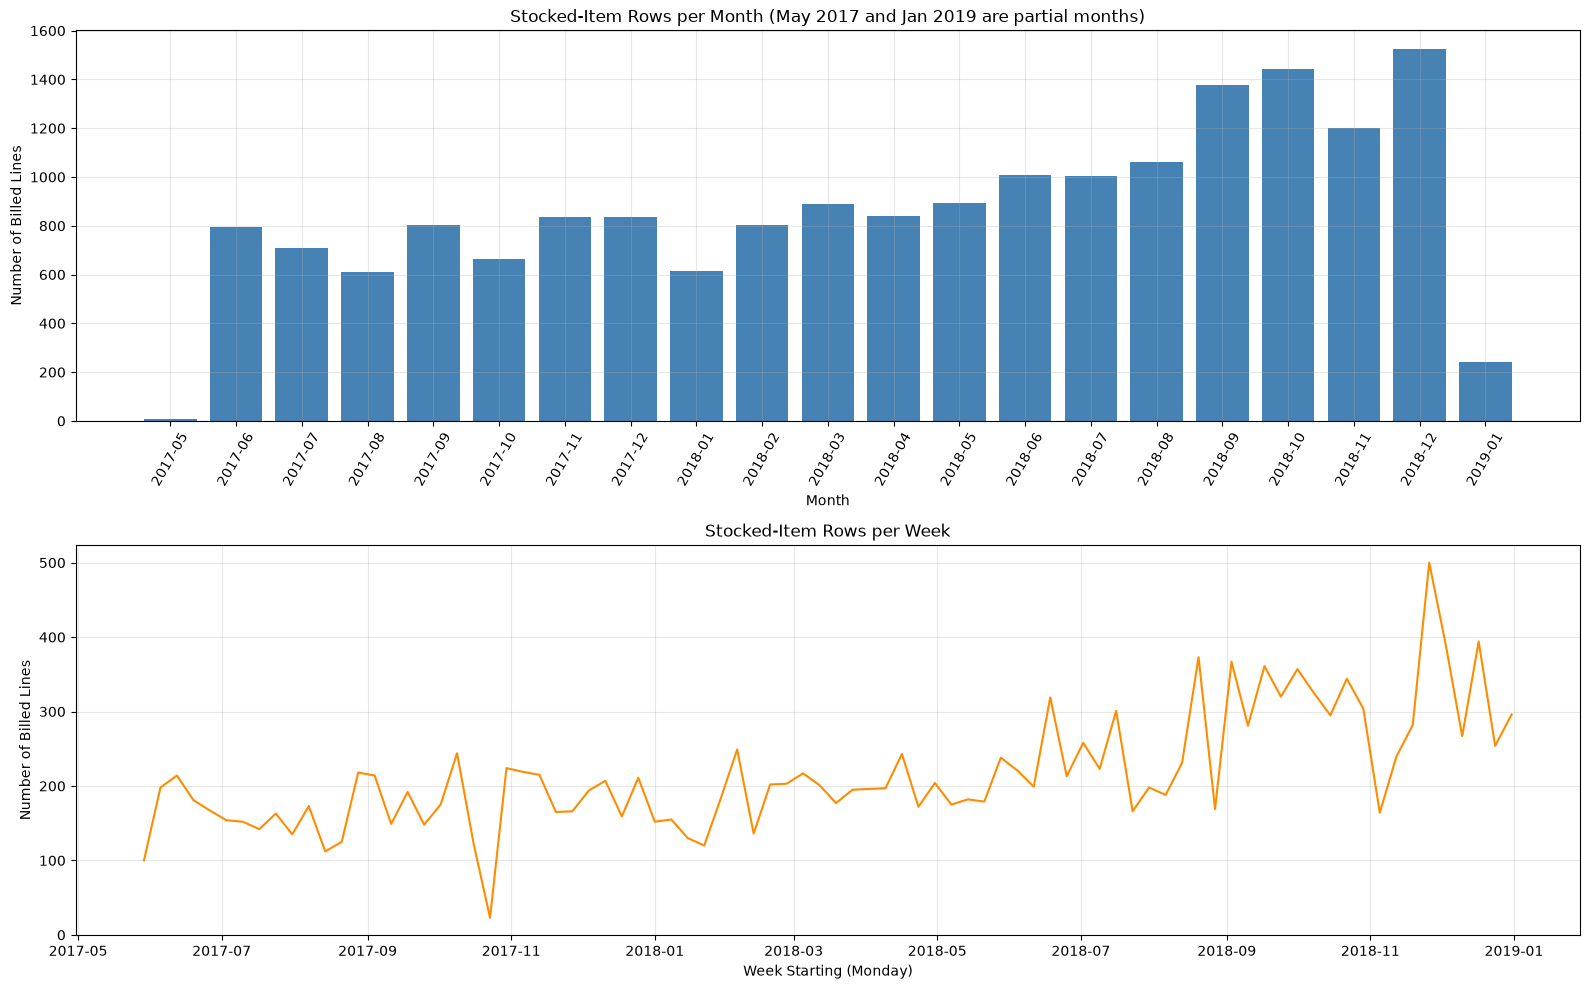

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Chart 1: rows per month
axes[0].bar(monthly.index.astype(str), monthly.values, color="steelblue")
axes[0].set_title("Stocked-Item Rows per Month (May 2017 and Jan 2019 are partial months)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Billed Lines")
axes[0].tick_params(axis="x", rotation=60)
axes[0].grid(True, alpha=0.3)

# Chart 2: rows per week
axes[1].plot(weekly.index, weekly.values, color="darkorange")
axes[1].set_title("Stocked-Item Rows per Week")
axes[1].set_xlabel("Week Starting (Monday)")
axes[1].set_ylabel("Number of Billed Lines")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Unusually Low and High Weeks

In [ ]:
print("Lowest 5 weeks:")
print(weekly.nsmallest(5))

print("\nHighest 5 weeks:")
print(weekly.nlargest(5))

all_days = pd.date_range(df_demand["invoice_date"].min(), df_demand["invoice_date"].max(), freq="D")
daily = df_stock.groupby("invoice_date").size().reindex(all_days, fill_value=0)

lowest_week = weekly.idxmin()

print("\nDaily rows in the lowest week (starting", lowest_week.date(), "):")
print(daily[lowest_week: lowest_week + pd.Timedelta(days=6)])

zero_days = daily[daily == 0]

print("\nDays with zero stocked rows:", len(zero_days))
print(zero_days.index.strftime("%Y-%m-%d (%a)").tolist())

Lowest 5 weeks:
2017-10-23     23
2017-05-29    100
2017-08-14    112
2018-01-22    120
2017-10-16    123
dtype: int64

Highest 5 weeks:
2018-11-26    500
2018-12-17    394
2018-12-03    390
2018-08-20    373
2018-09-03    367
dtype: int64

Daily rows in the lowest week (starting 2017-10-23 ):
2017-10-23     0
2017-10-24     7
2017-10-25     0
2017-10-26     0
2017-10-27     0
2017-10-28     0
2017-10-29    16
Freq: D, dtype: int64

Days with zero stocked rows: 32
['2017-07-02 (Sun)', '2017-07-16 (Sun)', '2017-07-23 (Sun)', '2017-07-30 (Sun)', '2017-08-06 (Sun)', '2017-08-13 (Sun)', '2017-08-25 (Fri)', '2017-09-29 (Fri)', '2017-10-08 (Sun)', '2017-10-19 (Thu)', '2017-10-20 (Fri)', '2017-10-22 (Sun)', '2017-10-23 (Mon)', '2017-10-25 (Wed)', '2017-10-26 (Thu)', '2017-10-27 (Fri)', '2017-10-28 (Sat)', '2017-11-05 (Sun)', '2018-01-01 (Mon)', '2018-01-28 (Sun)', '2018-03-18 (Sun)', '2018-08-16 (Thu)', '2018-08-30 (Thu)', '2018-08-31 (Fri)', '2018-09-09 (Sun)', '2018-09-13 (Thu)', '2018-10-0

### Visits and Lines per Visit

In [ ]:
visit_cols = ["vehicle_no", "invoice_date", "current_km_reading"]

visits = df_demand.groupby(visit_cols).size().rename("lines").reset_index()
visits["month"] = visits["invoice_date"].dt.to_period("M")

by_month = visits.groupby("month").agg(
    visits=("lines", "size"),
    avg_lines=("lines", "mean")
)

print(by_month.round(2).to_string())

         visits  avg_lines
month                     
2017-05       5       2.20
2017-06     193       6.95
2017-07     188       6.26
2017-08     172       5.62
2017-09     206       6.14
2017-10     173       6.09
2017-11     217       6.25
2017-12     231       5.81
2018-01     168       5.94
2018-02     221       5.96
2018-03     235       6.28
2018-04     226       6.18
2018-05     233       6.21
2018-06     242       6.57
2018-07     225       6.78
2018-08     221       7.11
2018-09     230       8.67
2018-10     254       8.28
2018-11     209       8.45
2018-12     261       8.59
2019-01      41       8.44


In [ ]:
tmp = df_demand.assign(month=df_demand["invoice_date"].dt.to_period("M"))

by_class = tmp.groupby(["month", "item_class"]).size().unstack(fill_value=0)
by_class = by_class.div(by_month["visits"], axis=0)

print(by_class[["PART", "FLUID", "SERVICE"]].round(2).to_string())

item_class  PART  FLUID  SERVICE
month                           
2017-05     0.20   1.40     0.60
2017-06     2.33   1.79     2.79
2017-07     2.17   1.60     2.47
2017-08     2.21   1.34     2.05
2017-09     2.43   1.47     2.21
2017-10     2.34   1.51     2.23
2017-11     2.42   1.42     2.38
2017-12     2.22   1.41     2.17
2018-01     2.26   1.41     2.26
2018-02     2.20   1.43     2.33
2018-03     2.21   1.57     2.48
2018-04     2.17   1.54     2.45
2018-05     2.30   1.54     2.34
2018-06     2.74   1.43     2.36
2018-07     3.02   1.45     2.29
2018-08     3.24   1.57     2.28
2018-09     4.10   1.88     2.66
2018-10     3.87   1.81     2.59
2018-11     3.91   1.83     2.69
2018-12     4.02   1.82     2.73
2019-01     4.15   1.76     2.51


### Weekly Demand of the Most Frequent Stocked Items

In [ ]:
top14 = stock_counts.head(14).index

weekly_item = (
    df_stock[df_stock["item_std"].isin(top14)]
    .groupby(["week_start", "item_std"]).size()
    .unstack(fill_value=0)
    .reindex(all_weeks, fill_value=0)
)

item_summary = pd.DataFrame({
    "avg_per_week": weekly_item.mean().round(1),
    "zero_weeks": (weekly_item == 0).sum(),
    "max_week": weekly_item.max(),
}).sort_values("avg_per_week", ascending=False)

print("WEEKLY DEMAND OF THE TOP 14 STOCKED ITEMS")
print("=" * 60)
print(item_summary)

WEEKLY DEMAND OF THE TOP 14 STOCKED ITEMS
                  avg_per_week  zero_weeks  max_week
item_std                                            
ENGINE OIL                45.0           0        67
AIR FILTER                20.2           3        42
3M OIL                    19.3           0        35
DISC OIL                  11.7           0        31
BRAKE SHOE                11.4           0        36
OIL FILTER                 9.7           1        28
DISC PAD                   7.6           1        18
WHEEL RUBBER               6.2           6        19
SPARK PLUG                 5.0           8        20
CHAIN SPROCKET             4.7           1        12
SPROCKET RUBBER            4.1          63        34
CLUTCH CABLE               4.1           4        10
SPROCKET BEARING           3.7          55        32
CLUTCH ASSEMBLY            2.5          12        10


In [ ]:
first_last = pd.DataFrame({
    "first_week": weekly_item.apply(lambda series: series[series > 0].index.min()),
    "last_week": weekly_item.apply(lambda series: series[series > 0].index.max()),
    "weeks_with_rows": (weekly_item > 0).sum(),
})

print(first_last)

sprocket = df_stock[
    df_stock["item_std"].isin(["SPROCKET RUBBER", "SPROCKET BEARING", "CHAIN SPROCKET"])
]

print("\nSprocket items per month:")
print(sprocket.groupby(["month", "item_std"]).size().unstack(fill_value=0).to_string())

                 first_week  last_week  weeks_with_rows
item_std                                               
3M OIL           2017-05-29 2018-12-31               84
AIR FILTER       2017-05-29 2018-12-31               81
BRAKE SHOE       2017-05-29 2018-12-31               84
CHAIN SPROCKET   2017-06-05 2018-12-31               83
CLUTCH ASSEMBLY  2017-05-29 2018-12-31               72
CLUTCH CABLE     2017-05-29 2018-12-31               80
DISC OIL         2017-05-29 2018-12-31               84
DISC PAD         2017-05-29 2018-12-31               83
ENGINE OIL       2017-05-29 2018-12-31               84
OIL FILTER       2017-05-29 2018-12-31               83
SPARK PLUG       2017-05-29 2018-12-31               76
SPROCKET BEARING 2017-06-26 2018-12-31               29
SPROCKET RUBBER  2018-04-09 2018-12-31               21
WHEEL RUBBER     2017-05-29 2018-12-17               78

Sprocket items per month:
item_std  CHAIN SPROCKET  SPROCKET BEARING  SPROCKET RUBBER
month            

## Task 2: Weekly Spare-Parts Demand Forecasting

### Selecting Regular Items and Break Items

In [ ]:
regular_items = [
    "ENGINE OIL", "AIR FILTER", "3M OIL", "DISC OIL", "BRAKE SHOE", "OIL FILTER",
    "DISC PAD", "WHEEL RUBBER", "SPARK PLUG", "CHAIN SPROCKET", "CLUTCH CABLE"
]
break_items = ["SPROCKET BEARING", "SPROCKET RUBBER"]

monthly_items = (
    df_stock[df_stock["item_std"].isin(regular_items)]
    .groupby(["month", "item_std"]).size()
    .unstack(fill_value=0)[regular_items]
)

print("MONTHLY ROWS OF THE 11 REGULAR ITEMS")
print("=" * 60)
print(monthly_items.to_string())

MONTHLY ROWS OF THE 11 REGULAR ITEMS
item_std  ENGINE OIL  AIR FILTER  3M OIL  DISC OIL  BRAKE SHOE  OIL FILTER  DISC PAD  WHEEL RUBBER  SPARK PLUG  CHAIN SPROCKET  CLUTCH CABLE
month                                                                                                                                       
2017-05            5           0       2         0           0           1         0             0           0               0             0
2017-06          179           5      88        71          44          34        30            34           9               9            16
2017-07          172          34      75        51          35          21        31            31          11              19            22
2017-08          145          51      64        19          29          28        22            16           9              15            15
2017-09          187          77      81        32          36          25        25            26          18       

### Core Weekly Demand Series

In [ ]:
core = df_stock[~df_stock["item_std"].isin(break_items)]
weekly_core = core.groupby("week_start").size().reindex(all_weeks, fill_value=0)

print("CORE WEEKLY SERIES")
print("=" * 60)
print(weekly_core.describe())


def rows_in_window(frame, year):
    """Number of rows between 1 June and 31 December of the given year."""
    dates = frame["invoice_date"]
    return ((dates >= f"{year}-06-01") & (dates <= f"{year}-12-31")).sum()


print("\nLIKE-FOR-LIKE GROWTH (Jun-Dec 2017 vs Jun-Dec 2018)")
print("=" * 60)

for name, frame in [("All stocked", df_stock), ("Core (without 2 break items)", core)]:
    rows_2017, rows_2018 = rows_in_window(frame, 2017), rows_in_window(frame, 2018)
    print(f"{name}: 2017 = {rows_2017}, 2018 = {rows_2018}, growth = {rows_2018 / rows_2017 - 1:.1%}")

CORE WEEKLY SERIES
count     84.000000
mean     208.464286
std       66.754260
min       23.000000
25%      165.750000
50%      200.000000
75%      239.250000
max      434.000000
dtype: float64

LIKE-FOR-LIKE GROWTH (Jun-Dec 2017 vs Jun-Dec 2018)
All stocked: 2017 = 5254, 2018 = 8623, growth = 64.1%
Core (without 2 break items): 2017 = 5250, 2018 = 8007, growth = 52.5%


### Chronological Train and Test Split

In [ ]:
y = weekly_core.iloc[1:].copy()
y.index.name = "week_start"

N_TEST_WEEKS = 12

train = y.iloc[:-N_TEST_WEEKS]
test = y.iloc[-N_TEST_WEEKS:]

n_weeks = len(y)
window_A = (n_weeks - 2 * N_TEST_WEEKS, n_weeks - N_TEST_WEEKS)
window_B = (n_weeks - N_TEST_WEEKS, n_weeks)

print("DATASET SPLIT")
print("=" * 60)

print("Total weeks:", n_weeks)
print("Train:", train.index.min().date(), "to", train.index.max().date(), "| weeks:", len(train))
print("Test: ", test.index.min().date(), "to", test.index.max().date(), "| weeks:", len(test))

print("\nWindow A (validation) starts:", y.index[window_A[0]].date())
print("Window B (test) starts:      ", y.index[window_B[0]].date())

print("\nAverage weekly rows - train:", round(train.mean(), 1), "| test:", round(test.mean(), 1))
print("Average of the last 8 training weeks:", round(train.iloc[-8:].mean(), 1))

DATASET SPLIT
Total weeks: 83
Train: 2017-06-05 to 2018-10-08 | weeks: 71
Test:  2018-10-15 to 2018-12-31 | weeks: 12

Window A (validation) starts: 2018-07-23
Window B (test) starts:       2018-10-15

Average weekly rows - train: 199.2 | test: 272.5
Average of the last 8 training weeks: 296.1


### Forecast Evaluation Framework

All models are evaluated with **rolling one-week-ahead forecasts**: for every week, the model uses only the weeks before it (no look-ahead). The metrics are MAE, RMSE, WAPE (weighted absolute percentage error) and sMAPE. WAPE is the main metric because several weeks and items have very small values, which makes ordinary MAPE unstable.

In [ ]:
def evaluate(actual, pred):
    """Return MAE, RMSE, WAPE and sMAPE for a set of forecasts."""
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    error = actual - pred

    return {
        "MAE": round(np.mean(np.abs(error)), 1),
        "RMSE": round(np.sqrt(np.mean(error ** 2)), 1),
        "WAPE %": round(np.sum(np.abs(error)) / np.sum(actual) * 100, 1),
        "sMAPE %": round(np.mean(2 * np.abs(error) / (np.abs(actual) + np.abs(pred))) * 100, 1),
    }


def wape(actual, pred):
    """Weighted absolute percentage error (in percent)."""
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return np.abs(actual - pred).sum() / actual.sum() * 100


def rolling_forecast(series, n_test, method):
    """One-week-ahead forecasts for the last n_test weeks of a series."""
    predictions = []

    for i in range(len(series) - n_test, len(series)):
        history = series.iloc[:i]          
        predictions.append(method(history))

    return predictions


def one_step_run(method, series=None):
    """Wrap a one-step method so it can be scored on any window (start, end)."""
    series = y if series is None else series

    def run(start, end):
        predictions = [method(series.iloc[:i]) for i in range(start, end)]
        return evaluate(series.iloc[start:end].values, predictions), predictions

    return run


def exposure_run(rate_series, exposure_series, rate_method):
    """Forecast the weekly RATE from earlier weeks, then multiply by that week's exposure."""

    def run(start, end):
        predictions = [
            rate_method(rate_series.iloc[:i]) * exposure_series.iloc[i]
            for i in range(start, end)
        ]
        return evaluate(y.iloc[start:end].values, predictions), predictions

    return run


def summarise_runs(runs):
    """Score every run on window A and window B and return one comparison table."""
    rows = []

    for name, run in runs.items():
        metrics_a, _ = run(*window_A)
        metrics_b, _ = run(*window_B)

        rows.append({
            "Model": name,
            "MAE A": metrics_a["MAE"], "WAPE A %": metrics_a["WAPE %"],
            "MAE B": metrics_b["MAE"], "RMSE B": metrics_b["RMSE"],
            "WAPE B %": metrics_b["WAPE %"], "sMAPE B %": metrics_b["sMAPE %"],
        })

    table = pd.DataFrame(rows).set_index("Model")
    table["WAPE avg %"] = ((table["WAPE A %"] + table["WAPE B %"]) / 2).round(1)
    table["WAPE worst %"] = table[["WAPE A %", "WAPE B %"]].max(axis=1)

    return table


print("Evaluation framework created successfully.")

Evaluation framework created successfully.


### 1. Baseline Forecasting Methods

In [ ]:
methods = {
    "Naive (last week)":               lambda h: h.iloc[-1],
    "Moving average (4 weeks)":        lambda h: h.iloc[-4:].mean(),
    "Moving average (8 weeks)":        lambda h: h.iloc[-8:].mean(),
    "Mean of all history":             lambda h: h.mean(),
    "Seasonal naive (same week, 52w)": lambda h: h.iloc[-52],
}

rows = []

for name, method in methods.items():
    predictions = rolling_forecast(y, N_TEST_WEEKS, method)
    rows.append({"Model": name, **evaluate(test.values, predictions)})

baseline_results = pd.DataFrame(rows).set_index("Model")

print("BASELINE RESULTS (TEST WINDOW)")
print("=" * 60)
print(baseline_results)

BASELINE RESULTS (TEST WINDOW)
                                   MAE   RMSE  WAPE %  sMAPE %
Model                                                         
Naive (last week)                 82.5   95.7    30.3     30.2
Moving average (4 weeks)          69.2   91.1    25.4     25.0
Moving average (8 weeks)          63.9   79.4    23.4     23.2
Mean of all history               77.4   99.8    28.4     30.0
Seasonal naive (same week, 52w)  112.8  145.6    41.4     51.9


### Baseline Error Analysis

In [ ]:
preds_ma8 = rolling_forecast(y, N_TEST_WEEKS, methods["Moving average (8 weeks)"])
preds_naive = rolling_forecast(y, N_TEST_WEEKS, methods["Naive (last week)"])

compare = pd.DataFrame({
    "actual": test.values,
    "MA8_forecast": np.round(preds_ma8, 1),
    "MA8_error": np.round(test.values - np.array(preds_ma8), 1),   
    "naive_forecast": np.round(preds_naive, 1),
}, index=test.index)

zero_days_per_week = (daily == 0).groupby(daily.index.to_period("W").start_time).sum()
compare["zero_days"] = zero_days_per_week.reindex(test.index).values

print("WEEK-BY-WEEK BASELINE COMPARISON")
print("=" * 60)
print(compare.to_string())

print("\nMean error of MA8 (negative = over-forecast):", round(compare["MA8_error"].mean(), 1))

WEEK-BY-WEEK BASELINE COMPARISON
            actual  MA8_forecast  MA8_error  naive_forecast  zero_days
week_start                                                            
2018-10-15     265         296.1      -31.1             295          0
2018-10-22     308         282.9       25.1             265          0
2018-10-29     265         300.4      -35.4             308          0
2018-11-05     149         291.6     -142.6             265          3
2018-11-12     214         277.8      -63.8             149          0
2018-11-19     244         264.4      -20.4             214          0
2018-11-26     434         258.0      176.0             244          0
2018-12-03     352         271.8       80.2             434          1
2018-12-10     224         278.9      -54.9             352          0
2018-12-17     338         273.8       64.2             224          0
2018-12-24     222         277.5      -55.5             338          0
2018-12-31     255         272.1      -17.1 

### Baseline Forecast Visualization

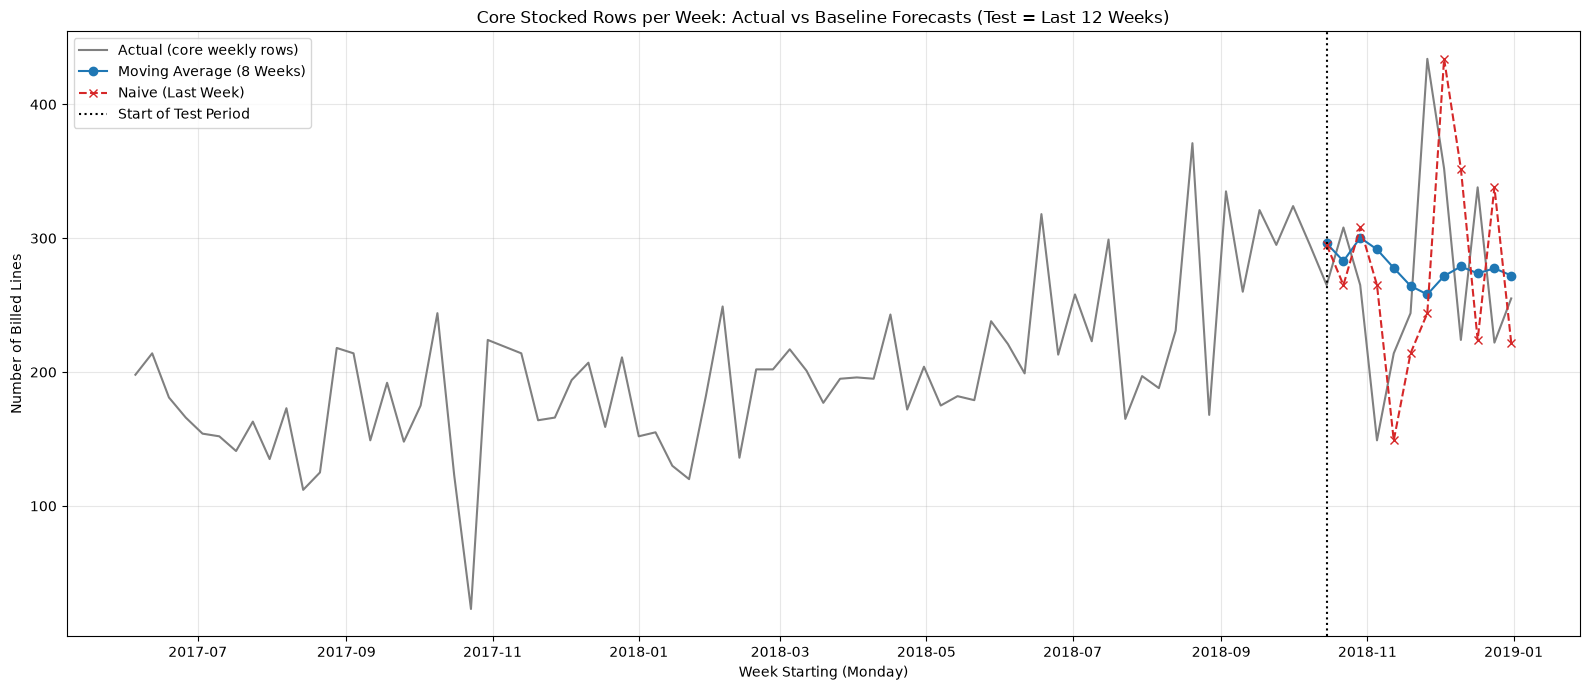

In [ ]:
fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(y.index, y.values, color="gray", label="Actual (core weekly rows)")
ax.plot(test.index, preds_ma8, color="tab:blue", marker="o", label="Moving Average (8 Weeks)")
ax.plot(test.index, preds_naive, color="tab:red", marker="x", linestyle="--", label="Naive (Last Week)")
ax.axvline(test.index.min(), color="black", linestyle=":", label="Start of Test Period")

ax.set_title("Core Stocked Rows per Week: Actual vs Baseline Forecasts (Test = Last 12 Weeks)")
ax.set_xlabel("Week Starting (Monday)")
ax.set_ylabel("Number of Billed Lines")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2. Exponential Smoothing Models

In [ ]:
try:
    import statsmodels
    from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
    from statsmodels.tsa.arima.model import ARIMA
    print("statsmodels version:", statsmodels.__version__)
except ImportError as error:
    raise ImportError("statsmodels is required. Install it with: pip install statsmodels") from error

warnings.filterwarnings("ignore")


def ses(history):
    """Simple exponential smoothing: one-step-ahead forecast."""
    return SimpleExpSmoothing(np.asarray(history, float), initialization_method="estimated").fit().forecast(1)[0]


def holt(history):
    """Holt linear trend: one-step-ahead forecast."""
    return ExponentialSmoothing(
        np.asarray(history, float), trend="add", initialization_method="estimated"
    ).fit().forecast(1)[0]


def holt_damped(history):
    """Holt damped trend: one-step-ahead forecast."""
    return ExponentialSmoothing(
        np.asarray(history, float), trend="add", damped_trend=True, initialization_method="estimated"
    ).fit().forecast(1)[0]


methods.update({
    "Simple exp. smoothing": ses,
    "Holt (trend)": holt,
    "Holt (damped trend)": holt_damped,
})

all_results = summarise_runs({name: one_step_run(method) for name, method in methods.items()})

print("BASELINES AND EXPONENTIAL SMOOTHING")
print("=" * 60)
print(all_results.sort_values("WAPE B %").to_string())

statsmodels version: 0.15.0
BASELINES AND EXPONENTIAL SMOOTHING
                                 MAE A  WAPE A %  MAE B  RMSE B  WAPE B %  sMAPE B %  WAPE avg %  WAPE worst %
Model                                                                                                         
Simple exp. smoothing             56.9      21.7   60.0    77.9      22.0       21.9        21.8          22.0
ARIMA(0,1,1)                      56.5      21.5   60.3    78.2      22.1       22.0        21.8          22.1
ARIMA(1,1,1)                      57.4      21.9   62.0    79.8      22.7       22.6        22.3          22.7
Moving average (8 weeks)          57.5      21.9   63.9    79.4      23.4       23.2        22.6          23.4
Holt (damped trend)               54.0      20.6   64.3    80.9      23.6       23.3        22.1          23.6
Holt (trend)                      53.2      20.3   65.7    81.2      24.1       23.8        22.2          24.1
Moving average (4 weeks)          52.4      19.9

### 3. ARIMA Models

In [ ]:
def arima_011(history):
    """ARIMA(0,1,1): one-step-ahead forecast."""
    return ARIMA(np.asarray(history, float), order=(0, 1, 1)).fit().forecast(1)[0]


def arima_111(history):
    """ARIMA(1,1,1): one-step-ahead forecast."""
    return ARIMA(np.asarray(history, float), order=(1, 1, 1)).fit().forecast(1)[0]


arima_methods = {"ARIMA(0,1,1)": arima_011, "ARIMA(1,1,1)": arima_111}
methods.update(arima_methods)

arima_results = summarise_runs({name: one_step_run(method) for name, method in arima_methods.items()})
all_results = pd.concat([all_results, arima_results])

print("ALL STATISTICAL MODELS (SORTED BY WORST-WINDOW WAPE)")
print("=" * 60)
print(all_results.sort_values("WAPE worst %").to_string())

ses_fit = SimpleExpSmoothing(np.asarray(train, float), initialization_method="estimated").fit()
alpha = ses_fit.params["smoothing_level"]

print("\nSES smoothing level (alpha):", round(alpha, 3),
      "| rough memory in weeks (1/alpha):", round(1 / alpha, 1))

ALL STATISTICAL MODELS (SORTED BY WORST-WINDOW WAPE)
                                 MAE A  WAPE A %  MAE B  RMSE B  WAPE B %  sMAPE B %  WAPE avg %  WAPE worst %
Model                                                                                                         
Simple exp. smoothing             56.9      21.7   60.0    77.9      22.0       21.9        21.8          22.0
ARIMA(0,1,1)                      56.5      21.5   60.3    78.2      22.1       22.0        21.8          22.1
ARIMA(0,1,1)                      56.5      21.5   60.3    78.2      22.1       22.0        21.8          22.1
ARIMA(1,1,1)                      57.4      21.9   62.0    79.8      22.7       22.6        22.3          22.7
ARIMA(1,1,1)                      57.4      21.9   62.0    79.8      22.7       22.6        22.3          22.7
Moving average (8 weeks)          57.5      21.9   63.9    79.4      23.4       23.2        22.6          23.4
Holt (damped trend)               54.0      20.6   64.3    

### 4. Calendar Adjustment: Open Days

In [ ]:
open_days = (daily > 0).groupby(daily.index.to_period("W").start_time).sum().reindex(y.index)
rate = y / open_days                                   

print("Number of weeks by open days:")
print(open_days.value_counts().sort_index())
print("\nWeeks with fewer than 7 open days:", (open_days < 7).sum())

open_day_runs = {
    "SES on rate x open days": exposure_run(rate, open_days, ses),
    "MA8 on rate x open days": exposure_run(rate, open_days, lambda h: h.iloc[-8:].mean()),
}

open_day_results = summarise_runs(open_day_runs)
all_results = pd.concat([all_results, open_day_results])

print("\nRESULTS WITH OPEN-DAY ADJUSTMENT (SORTED BY WORST-WINDOW WAPE)")
print("=" * 60)
print(all_results.sort_values("WAPE worst %").to_string())

_, preds_ses_cal = open_day_runs["SES on rate x open days"](*window_B)
preds_ses = [ses(y.iloc[:i]) for i in range(*window_B)]

weekly_view = pd.DataFrame({
    "actual": y.iloc[window_B[0]:window_B[1]].values,
    "SES": np.round(preds_ses, 1),
    "SES_calendar": np.round(preds_ses_cal, 1),
    "open_days": open_days.iloc[window_B[0]:window_B[1]].values,
}, index=test.index)

print("\nWEEK-BY-WEEK VIEW OF THE TEST PERIOD")
print("=" * 60)
print(weekly_view.to_string())

Number of weeks by open days:
2     1
4     2
5     1
6    19
7    60
Name: count, dtype: int64

Weeks with fewer than 7 open days: 23

RESULTS WITH OPEN-DAY ADJUSTMENT (SORTED BY WORST-WINDOW WAPE)
                                 MAE A  WAPE A %  MAE B  RMSE B  WAPE B %  sMAPE B %  WAPE avg %  WAPE worst %
Model                                                                                                         
SES on rate x open days           51.2      19.5   58.4    74.4      21.4       20.4        20.4          21.4
Simple exp. smoothing             56.9      21.7   60.0    77.9      22.0       21.9        21.8          22.0
ARIMA(0,1,1)                      56.5      21.5   60.3    78.2      22.1       22.0        21.8          22.1
ARIMA(0,1,1)                      56.5      21.5   60.3    78.2      22.1       22.0        21.8          22.1
MA8 on rate x open days           56.0      21.3   60.6    73.6      22.2       21.3        21.8          22.2
ARIMA(1,1,1)            

### 5. Calendar Adjustment: Weekday-Weighted Exposure

In [ ]:
cutoff = y.index[window_A[0]]
hist_daily = daily[(daily.index >= y.index[0]) & (daily.index < cutoff)]
open_hist = hist_daily[hist_daily > 0]                       

weekday_weights = open_hist.groupby(open_hist.index.dayofweek).mean()   
weekday_weights = weekday_weights / weekday_weights.sum()               

print("Weekday weights (%):")
print((weekday_weights * 100).round(1))

is_open = daily > 0
day_weight = is_open * is_open.index.dayofweek.map(weekday_weights).values
exposure = day_weight.groupby(day_weight.index.to_period("W").start_time).sum().reindex(y.index)

assert (exposure > 0).all(), "Some weeks have zero exposure; the rate cannot be calculated."

rate_w = y / exposure

weighted_runs = {
    "SES on rate x weighted exposure": exposure_run(rate_w, exposure, ses),
    "MA8 on rate x weighted exposure": exposure_run(rate_w, exposure, lambda h: h.iloc[-8:].mean()),
}

weighted_results = summarise_runs(weighted_runs)
all_results = pd.concat([all_results, weighted_results])

print("\nRESULTS WITH WEIGHTED EXPOSURE (SORTED BY WORST-WINDOW WAPE)")
print("=" * 60)
print(all_results.sort_values("WAPE worst %").to_string())

# 4) Week-by-week view of the test period
_, preds_ses_calw = weighted_runs["SES on rate x weighted exposure"](*window_B)

weekly_view["SES_weighted_cal"] = np.round(preds_ses_calw, 1)
weekly_view["exposure"] = exposure.iloc[window_B[0]:window_B[1]].round(3).values

print("\nWEEK-BY-WEEK VIEW OF THE TEST PERIOD")
print("=" * 60)
print(weekly_view.to_string())

Weekday weights (%):
0    14.1
1    15.1
2    13.9
3    14.3
4    14.3
5    19.6
6     8.7
dtype: float64

RESULTS WITH WEIGHTED EXPOSURE (SORTED BY WORST-WINDOW WAPE)
                                 MAE A  WAPE A %  MAE B  RMSE B  WAPE B %  sMAPE B %  WAPE avg %  WAPE worst %
Model                                                                                                         
SES on rate x weighted exposure   49.1      18.7   56.5    72.2      20.7       19.8        19.7          20.7
SES on rate x open days           51.2      19.5   58.4    74.4      21.4       20.4        20.4          21.4
MA8 on rate x weighted exposure   54.0      20.6   58.3    70.8      21.4       20.5        21.0          21.4
Simple exp. smoothing             56.9      21.7   60.0    77.9      22.0       21.9        21.8          22.0
ARIMA(0,1,1)                      56.5      21.5   60.3    78.2      22.1       22.0        21.8          22.1
ARIMA(0,1,1)                      56.5      21.5   60.3

### Surge Week Analysis (26 November 2018)

In [ ]:
surge = pd.Timestamp("2018-11-26")
diwali = pd.Timestamp("2018-11-05")

previous_weeks = [
    week for week in pd.date_range(end=surge - pd.Timedelta(days=7), periods=9, freq="7D")
    if week != diwali
]

by_item_week = core.groupby(["week_start", "item_std"]).size().unstack(fill_value=0)

surge_table = pd.DataFrame({
    "surge_week": by_item_week.loc[surge],
    "avg_prev_8_weeks": by_item_week.loc[previous_weeks].mean().round(1),
})
surge_table["extra"] = (surge_table["surge_week"] - surge_table["avg_prev_8_weeks"]).round(1)

print("SURGE WEEK: ITEMS WITH THE LARGEST INCREASE")
print("=" * 60)
print(surge_table.sort_values("extra", ascending=False).head(12))

print("\nTotal extra lines vs the previous 8-week average:", round(surge_table["extra"].sum(), 1))
print("Items with extra > 0:", (surge_table["extra"] > 0).sum(), "of", len(surge_table))

SURGE WEEK: ITEMS WITH THE LARGEST INCREASE
                     surge_week  avg_prev_8_weeks  extra
item_std                                                
BRAKE SHOE                   36              16.0   20.0
OIL FILTER                   28              13.0   15.0
ENGINE OIL                   67              53.0   14.0
AIR FILTER                   41              30.8   10.2
CLUTCH ASSEMBLY              10               3.2    6.8
DISC OIL                     28              21.4    6.6
3M OIL                       30              24.2    5.8
CLUTCH COVER GASKET           9               3.8    5.2
TIMING CHAIN                  5               0.9    4.1
CHAIN SPROCKET               11               6.9    4.1
TENSIONER                     5               0.9    4.1
CAM SHAFT                     4               0.2    3.8

Total extra lines vs the previous 8-week average: 160.2
Items with extra > 0: 83 of 412


### 6. Machine Learning Models

In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

feat = pd.DataFrame({"rate": rate_w})

for lag in range(1, 5):
    feat[f"lag_{lag}"] = feat["rate"].shift(lag)

feat["roll4"] = feat["rate"].shift(1).rolling(4).mean()
feat["roll8"] = feat["rate"].shift(1).rolling(8).mean()

print("LEAKAGE CHECK")
print("=" * 60)
print("roll4 at row 8:", round(feat["roll4"].iloc[8], 3),
      "| mean of rate rows 4-7:", round(feat["rate"].iloc[4:8].mean(), 3))
print(feat.iloc[8:11].round(1))


def ml_run(model_factory):
    """Rolling one-week-ahead evaluation: refit on earlier weeks, predict the rate, multiply by exposure."""

    def run(start, end):
        predictions = []

        for i in range(start, end):
            train_rows = feat.iloc[8:i]                              
            X_train_ml, y_train_ml = train_rows.drop(columns="rate"), train_rows["rate"]

            model = model_factory().fit(X_train_ml, y_train_ml)

            x_week = feat.iloc[[i]].drop(columns="rate")             
            predictions.append(model.predict(x_week)[0] * exposure.iloc[i])

        return evaluate(y.iloc[start:end].values, predictions), predictions

    return run


def make_random_forest():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)


def make_gradient_boosting():
    return GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)


ml_runs = {
    "Random Forest (lags, weighted exposure)": ml_run(make_random_forest),
    "Gradient Boosting (lags, weighted exposure)": ml_run(make_gradient_boosting),
}

ml_results = summarise_runs(ml_runs)
all_results = pd.concat([all_results, ml_results])

print("\nTOP 8 MODELS (SORTED BY WORST-WINDOW WAPE)")
print("=" * 60)
print(all_results.sort_values("WAPE worst %").head(8).to_string())

print("\nMACHINE LEARNING MODELS")
print("=" * 60)
print(ml_results.to_string())

LEAKAGE CHECK
roll4 at row 8: 163.403 | mean of rate rows 4-7: 163.403
             rate  lag_1  lag_2  lag_3  lag_4  roll4  roll8
week_start                                                 
2017-07-31  147.9  178.6  154.5  166.5  154.0  163.4  178.6
2017-08-07  189.5  147.9  178.6  154.5  166.5  161.9  172.3
2017-08-14  112.0  189.5  147.9  178.6  154.5  167.6  169.2

TOP 8 MODELS (SORTED BY WORST-WINDOW WAPE)
                                         MAE A  WAPE A %  MAE B  RMSE B  WAPE B %  sMAPE B %  WAPE avg %  WAPE worst %
Model                                                                                                                 
SES on rate x weighted exposure           49.1      18.7   56.5    72.2      20.7       19.8        19.7          20.7
SES on rate x open days                   51.2      19.5   58.4    74.4      21.4       20.4        20.4          21.4
MA8 on rate x weighted exposure           54.0      20.6   58.3    70.8      21.4       20.5        21.0     

### Random Forest Feature Importance

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,roll4,0.406
1,roll8,0.242
2,lag_4,0.106
3,lag_1,0.099
4,lag_2,0.079
5,lag_3,0.068


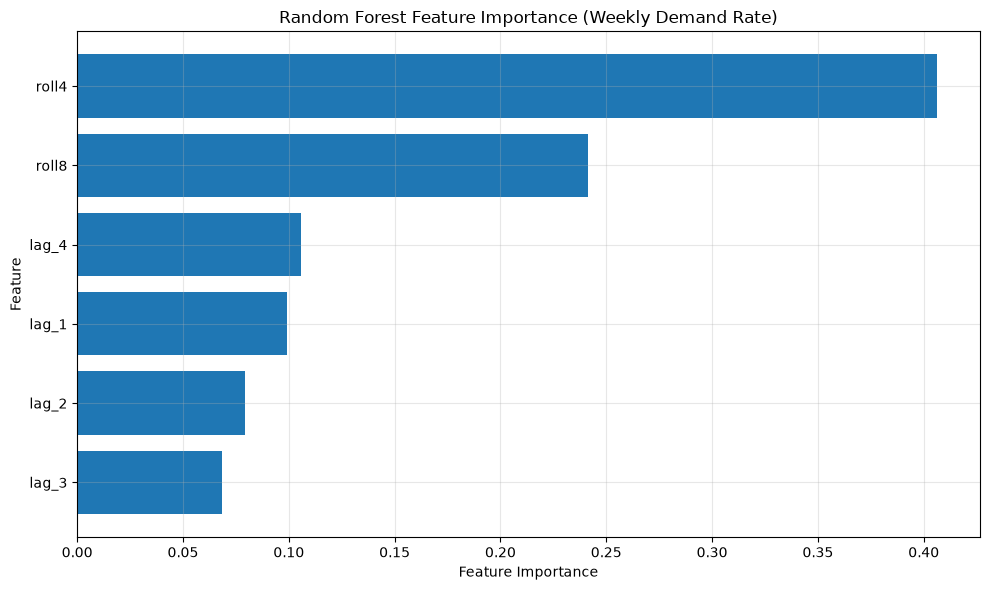

In [ ]:
train_rows = feat.iloc[8:window_B[0]]
X_importance, y_importance = train_rows.drop(columns="rate"), train_rows["rate"]

rf_importance_model = make_random_forest().fit(X_importance, y_importance)

feature_importance = (
    pd.Series(rf_importance_model.feature_importances_, index=X_importance.columns)
    .sort_values(ascending=False)
    .rename("Importance")
    .reset_index()
    .rename(columns={"index": "Feature"})
)

print("RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 60)
display(feature_importance.round(3))

plt.figure(figsize=(10, 6))

plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance (Weekly Demand Rate)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 7. Item-Level Forecasting

In [ ]:
items_y = weekly_item[regular_items].iloc[1:].copy()
assert (items_y.index == y.index).all()          

forecast_kinds = ["MA8", "SES", "SES weighted"]


def run_item(series, kind, start, end):
    """One-week-ahead rolling forecasts for one item. Returns (actual, predicted)."""
    predictions = []

    for i in range(start, end):
        history = series.iloc[:i]                         

        if kind == "MA8":
            prediction = history.iloc[-8:].mean()
        elif kind == "SES":
            prediction = ses(history)
        else:                                              
            prediction = ses(history / exposure.iloc[:i]) * exposure.iloc[i]

        predictions.append(prediction)

    return series.iloc[start:end].values, np.array(predictions)


item_runs = {}

for item in regular_items:
    for kind in forecast_kinds:
        for label, window in [("A", window_A), ("B", window_B)]:
            item_runs[(item, kind, label)] = run_item(items_y[item], kind, *window)

item_wape_table = pd.DataFrame({
    f"{kind} {label}": {item: round(wape(*item_runs[(item, kind, label)]), 1) for item in regular_items}
    for kind in forecast_kinds for label in ["A", "B"]
})

item_wape_table.insert(
    0, "avg/week (test)",
    [round(items_y[item].iloc[window_B[0]:].mean(), 1) for item in item_wape_table.index]
)

print("ITEM-LEVEL WAPE (%)")
print("=" * 60)
print(item_wape_table.to_string())

print("\nOVERALL ITEM-LEVEL WAPE")
print("=" * 60)

for kind in forecast_kinds:
    for label in ["A", "B"]:
        errors = sum(np.abs(a - p).sum() for a, p in (item_runs[(i, kind, label)] for i in regular_items))
        totals = sum(a.sum() for a, p in (item_runs[(i, kind, label)] for i in regular_items))
        print(f"{kind:13s} window {label}: overall WAPE {errors / totals * 100:.1f}%")

ITEM-LEVEL WAPE (%)
                avg/week (test)  MA8 A  MA8 B  SES A  SES B  SES weighted A  SES weighted B
ENGINE OIL                 50.1   17.5   16.2   16.0   16.9            15.0            12.2
AIR FILTER                 30.1   23.2   20.4   24.9   20.7            22.9            18.9
3M OIL                     23.8   24.3   28.7   25.0   30.2            24.4            25.9
DISC OIL                   19.4   41.3   28.4   23.9   31.4            23.8            29.4
BRAKE SHOE                 13.9   26.5   46.5   26.7   42.2            25.1            41.2
OIL FILTER                 14.8   20.7   28.9   22.8   28.7            27.6            27.6
DISC PAD                    7.9   37.7   47.6   38.3   40.7            40.0            40.2
WHEEL RUBBER                1.4   42.4  144.1   35.2  109.5            35.6           104.8
SPARK PLUG                  7.3   26.6   67.2   26.0   65.4            23.5            64.8
CHAIN SPROCKET              6.8   49.6   36.6   53.2   34.3 

### Final Model Visualization: Actual vs Forecast

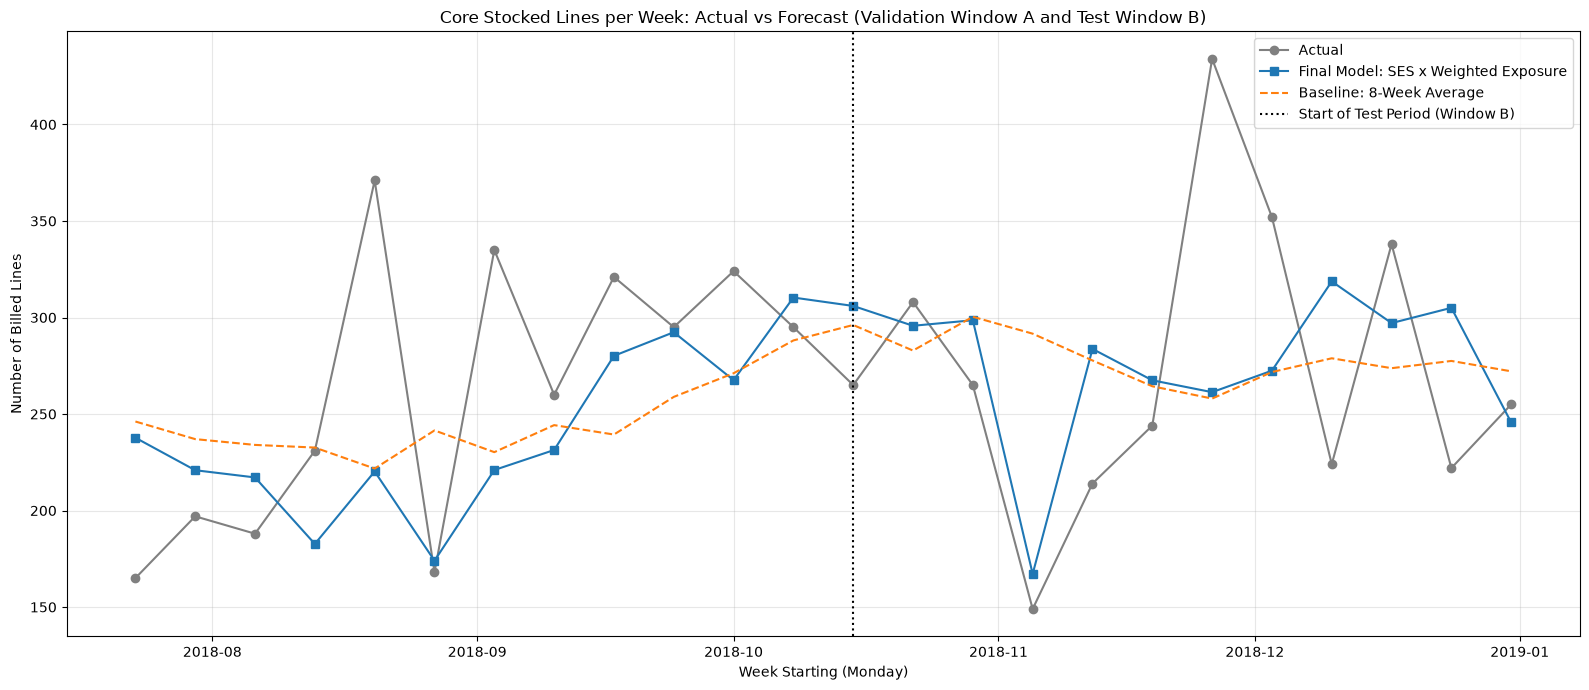

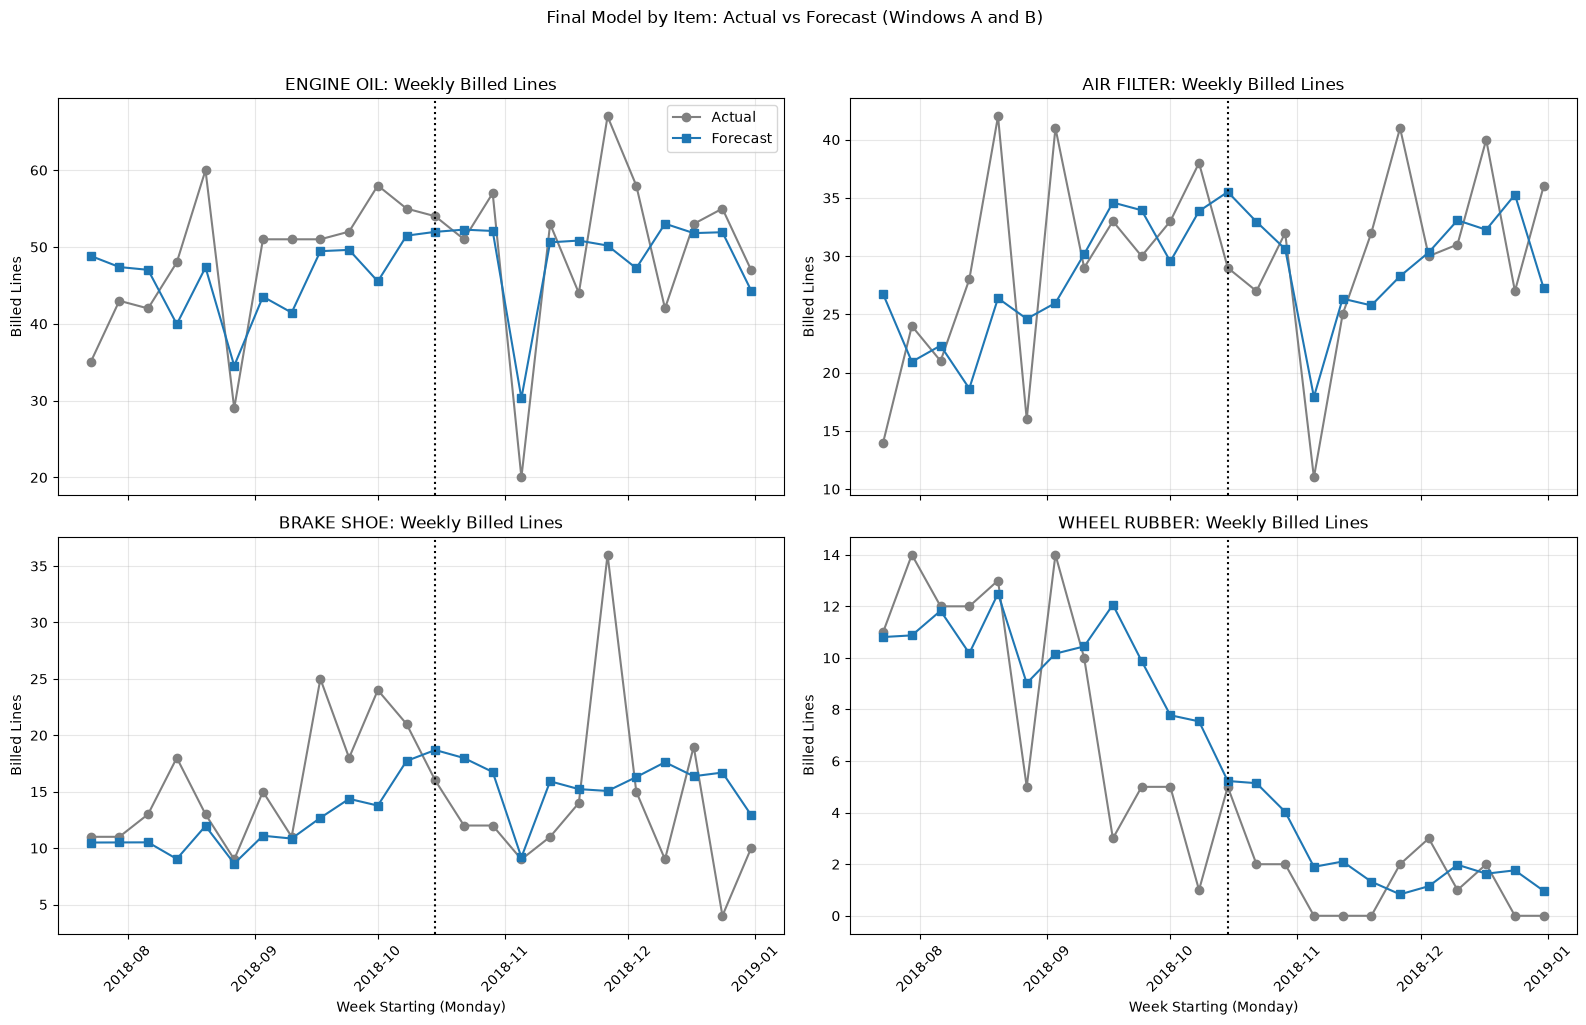

In [ ]:
weeks_AB = y.index[window_A[0]:window_B[1]]                    

_, pred_a = weighted_runs["SES on rate x weighted exposure"](*window_A)
_, pred_b = weighted_runs["SES on rate x weighted exposure"](*window_B)

final_total = np.array(pred_a + pred_b)
ma8_total = np.array(rolling_forecast(y, 2 * N_TEST_WEEKS, methods["Moving average (8 weeks)"]))
actual_total = y.iloc[window_A[0]:window_B[1]].values

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(weeks_AB, actual_total, color="gray", marker="o", label="Actual")
ax.plot(weeks_AB, final_total, color="tab:blue", marker="s", label="Final Model: SES x Weighted Exposure")
ax.plot(weeks_AB, ma8_total, color="tab:orange", linestyle="--", label="Baseline: 8-Week Average")
ax.axvline(test.index.min(), color="black", linestyle=":", label="Start of Test Period (Window B)")

ax.set_title("Core Stocked Lines per Week: Actual vs Forecast (Validation Window A and Test Window B)")
ax.set_xlabel("Week Starting (Monday)")
ax.set_ylabel("Number of Billed Lines")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_core_actual_vs_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

show_items = ["ENGINE OIL", "AIR FILTER", "BRAKE SHOE", "WHEEL RUBBER"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True)

for ax, item in zip(axes.ravel(), show_items):
    actual_a, forecast_a = item_runs[(item, "SES weighted", "A")]
    actual_b, forecast_b = item_runs[(item, "SES weighted", "B")]

    ax.plot(weeks_AB, np.concatenate([actual_a, actual_b]), color="gray", marker="o", label="Actual")
    ax.plot(weeks_AB, np.concatenate([forecast_a, forecast_b]), color="tab:blue", marker="s", label="Forecast")
    ax.axvline(test.index.min(), color="black", linestyle=":")

    ax.set_title(f"{item}: Weekly Billed Lines")
    ax.set_ylabel("Billed Lines")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, alpha=0.3)

axes[0, 0].legend()

for ax in axes[1]:
    ax.set_xlabel("Week Starting (Monday)")

plt.suptitle("Final Model by Item: Actual vs Forecast (Windows A and B)", y=1.02)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_items_actual_vs_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

### Saving Results

In [ ]:
all_results.to_csv(TABLES_DIR / "model_comparison_core_total.csv")
item_wape_table.to_csv(TABLES_DIR / "item_level_results.csv")

y.to_pickle(PROCESSED_DIR / "core_weekly_series.pkl")
items_y.to_pickle(PROCESSED_DIR / "items_weekly_series.pkl")

print("Saved: 2 figures, 2 csv tables, 2 pickle files")
print("Figures:", FIGURES_DIR)
print("Tables: ", TABLES_DIR)
print("Series: ", PROCESSED_DIR)

Saved: 2 figures, 2 csv tables, 2 pickle files
Figures: c:\Users\meham\Downloads\outputs\figures
Tables:  c:\Users\meham\Downloads\outputs\tables
Series:  c:\Users\meham\Downloads\data\processed


### Final Model Comparison

In [ ]:
final_comparison = all_results.sort_values("WAPE worst %")

print("FINAL MODEL COMPARISON (CORE WEEKLY TOTAL)")
print("=" * 60)
display(final_comparison)

FINAL MODEL COMPARISON (CORE WEEKLY TOTAL)


,MAE A,WAPE A %,MAE B,RMSE B,WAPE B %,sMAPE B %,WAPE avg %,WAPE worst %
Model,,,,,,,,
SES on rate x weighted exposure,49.1,18.7,56.5,72.2,20.7,19.8,19.7,20.7
SES on rate x open days,51.2,19.5,58.4,74.4,21.4,20.4,20.4,21.4
MA8 on rate x weighted exposure,54.0,20.6,58.3,70.8,21.4,20.5,21.0,21.4
Simple exp. smoothing,56.9,21.7,60.0,77.9,22.0,21.9,21.8,22.0
"ARIMA(0,1,1)",56.5,21.5,60.3,78.2,22.1,22.0,21.8,22.1
MA8 on rate x open days,56.0,21.3,60.6,73.6,22.2,21.3,21.8,22.2
"Random Forest (lags, weighted exposure)",56.5,21.5,61.5,80.9,22.6,21.8,22.0,22.6
"ARIMA(1,1,1)",57.4,21.9,62.0,79.8,22.7,22.6,22.3,22.7
Moving average (8 weeks),57.5,21.9,63.9,79.4,23.4,23.2,22.6,23.4


### Robustness Check: Effect of Repeat Rows

In [ ]:
core_norep = core[~core["is_repeat_row"]]

y_norep = (
    core_norep.groupby("week_start").size()
    .reindex(all_weeks, fill_value=0)
    .iloc[1:]
)

print("Rows in core:", len(core), "| without repeat rows:", len(core_norep),
      "| removed:", len(core) - len(core_norep))


def score_three(series):
    """WAPE (windows A and B) for SES weighted, plain SES and the 8-week average on a given series."""
    rate_series = series / exposure
    scores = {}

    for label, (start, end) in {"A": window_A, "B": window_B}.items():
        actual = series.iloc[start:end].values

        pred_weighted = [ses(rate_series.iloc[:i]) * exposure.iloc[i] for i in range(start, end)]
        pred_plain = [ses(series.iloc[:i]) for i in range(start, end)]
        pred_ma8 = [series.iloc[:i].iloc[-8:].mean() for i in range(start, end)]

        scores[("SES weighted", label)] = round(wape(actual, pred_weighted), 1)
        scores[("Plain SES", label)] = round(wape(actual, pred_plain), 1)
        scores[("8-week average", label)] = round(wape(actual, pred_ma8), 1)

    return pd.Series(scores)


compare_repeats = pd.DataFrame({
    "With small repeats (our data)": score_three(y),
    "Without any repeats": score_three(y_norep),
})

print("\nWAPE (%) WITH AND WITHOUT REPEAT ROWS")
print("=" * 60)
print(compare_repeats.to_string())

Rows in core: 17511 | without repeat rows: 17309 | removed: 202

WAPE (%) WITH AND WITHOUT REPEAT ROWS
                  With small repeats (our data)  Without any repeats
SES weighted   A                           18.7                 18.2
Plain SES      A                           21.7                 21.1
8-week average A                           21.9                 21.4
SES weighted   B                           20.7                 20.4
Plain SES      B                           22.0                 21.7
8-week average B                           23.4                 23.0


### Robustness Check: Normal Weeks and Closure Weeks

In [ ]:
window_index = range(window_A[0], window_B[1])

actual_all = y.iloc[window_A[0]:window_B[1]].values
pred_final = final_total                                              
pred_plain_ses = np.array([ses(y.iloc[:i]) for i in window_index])    
pred_ma8 = ma8_total                                                  

normal = (exposure.iloc[window_A[0]:window_B[1]] >= 0.999).values

rows = []

for name, prediction in [
    ("SES x weighted exposure", pred_final),
    ("Plain SES", pred_plain_ses),
    ("8-week average", pred_ma8),
]:
    rows.append({
        "Model": name,
        "WAPE all 24 weeks": round(wape(actual_all, prediction), 1),
        f"WAPE normal weeks ({normal.sum()})": round(wape(actual_all[normal], prediction[normal]), 1),
        f"WAPE closure weeks ({(~normal).sum()})": round(wape(actual_all[~normal], prediction[~normal]), 1),
        "Mean error, normal weeks": round((actual_all[normal] - prediction[normal]).mean(), 1),
    })

normal_vs_closure = pd.DataFrame(rows).set_index("Model")

print("NORMAL WEEKS VS CLOSURE WEEKS (WINDOWS A AND B)")
print("=" * 60)
print(normal_vs_closure.to_string())

NORMAL WEEKS VS CLOSURE WEEKS (WINDOWS A AND B)
                         WAPE all 24 weeks  WAPE normal weeks (16)  WAPE closure weeks (8)  Mean error, normal weeks
Model                                                                                                               
SES x weighted exposure               19.7                    20.9                    17.4                      -4.2
Plain SES                             21.9                    20.7                    24.2                      13.8
8-week average                        22.7                    22.3                    23.6                       6.9


### Next-Week Forecast with Uncertainty Range

In [ ]:
next_week = y.index[-1] + pd.Timedelta(days=7)
exposure_next = 1.0           


def next_week_row(name, rate_history, actual_history, pred_history, test_wape):
    """Forecast for the next week with a range based on the past forecast errors."""
    forecast = ses(rate_history) * exposure_next
    errors = actual_history - pred_history

    return {
        "Series": name,
        "Forecast": round(forecast, 1),
        "Low (10th pct)": round(max(forecast + np.percentile(errors, 10), 0), 1),
        "High (90th pct)": round(forecast + np.percentile(errors, 90), 1),
        "Typical miss (MAE)": round(np.abs(errors).mean(), 1),
        "Test WAPE %": test_wape,
    }


core_test_wape = round(wape(y.iloc[window_B[0]:window_B[1]].values, pred_b), 1)

rows = [next_week_row("CORE TOTAL", rate_w, actual_total, final_total, core_test_wape)]

for item in regular_items:
    actual_a, forecast_a = item_runs[(item, "SES weighted", "A")]
    actual_b, forecast_b = item_runs[(item, "SES weighted", "B")]

    rows.append(next_week_row(
        item,
        items_y[item] / exposure,
        np.concatenate([actual_a, actual_b]),
        np.concatenate([forecast_a, forecast_b]),
        item_wape_table.loc[item, "SES weighted B"],
    ))

forecast_table = pd.DataFrame(rows).set_index("Series")

print("NEXT-WEEK FORECAST")
print("=" * 60)
print("Forecast for the week starting", next_week.date())
print("Assumed exposure of the week:", exposure_next)
print()
print(forecast_table.to_string())

forecast_table.to_csv(TABLES_DIR / "next_week_forecast.csv")

NEXT-WEEK FORECAST
Forecast for the week starting 2019-01-07
Assumed exposure of the week: 1.0

                Forecast  Low (10th pct)  High (90th pct)  Typical miss (MAE)  Test WAPE %
Series                                                                                    
CORE TOTAL         291.3           219.5            395.0                52.8         20.7
ENGINE OIL          52.5            43.3             64.5                 6.7         12.2
AIR FILTER          35.9            28.0             47.6                 6.2         18.9
3M OIL              23.9            17.7             35.0                 5.6         25.9
DISC OIL            23.3            16.8             30.1                 4.9         29.4
BRAKE SHOE          14.9             9.2             24.7                 4.8         41.2
OIL FILTER          15.4            10.8             21.5                 3.6         27.6
DISC PAD             8.9             5.2             14.3                 3.5        

# Task 3: Inventory and Operations Recommendations

The following recommendations are based on the results of the analysis above. The forecast figures come from the final model (SES on rate with weekly weighted exposure) and assume that the coming week is a full working week.

**1. Plan Weekly Stock Orders Using the Forecast Range, Not Only the Point Forecast**

For the week starting 7 January 2019 the model forecasts about 291 core stocked lines, with a 10th to 90th percentile range of roughly 220 to 395 lines. Ordering should cover the upper part of this range for items where a stock-out is costly, because the typical miss for the total is about 53 lines per week.

**2. Use the Item Forecasts for High-Volume Regular Items**

ENGINE OIL, AIR FILTER, 3M OIL, OIL FILTER and DISC OIL have test WAPE values between 12% and 29%, so their weekly forecasts (for example about 52 lines for ENGINE OIL and about 36 for AIR FILTER) can support regular replenishment.

**3. Use Safety-Stock Rules for Low-Volume and Erratic Items**

BRAKE SHOE, DISC PAD, CLUTCH CABLE, SPARK PLUG and WHEEL RUBBER have test WAPE values of 40% or more. For these items, a minimum and maximum stock level based on recent usage is more reliable than a weekly point forecast.

**4. Feed the Planned Working Days into the Forecast**

Closure weeks are the main source of error for simple models. Entering the expected number of open days (for example, around Diwali) reduces the error in those weeks, so the workshop calendar should be recorded and used when planning orders.

**5. Prepare for Demand Surges and Monitor Level Shifts**

The week of 26 November 2018 shows that a broad surge can raise demand by roughly 160 lines above normal. The cause is not visible in the data, so a buffer for the largest movers (BRAKE SHOE, OIL FILTER, ENGINE OIL) is advisable. Items with sudden changes in demand, such as SPROCKET BEARING, SPROCKET RUBBER and WHEEL RUBBER, should be reviewed manually.

**6. Improve Data Capture**

The analysis required removing block-repeated invoice lines, correcting misspelled item names, flagging zero or impossible kilometre readings and handling blank item names. A fixed item list in the billing system, validation of kilometre readings and prevention of duplicate invoice entry would remove most of this cleaning work.

**7. Refresh the Model Regularly**

Because the model remembers only about the last six weeks, it should be refitted every week with the newest data and re-evaluated each month to confirm that the error stays near the levels reported here.

# Challenges Faced and Techniques Used

During the development of the New X Services analysis, several challenges were encountered during data preparation and demand forecasting. The following techniques were applied to address these challenges.

| Challenge | Technique Used | Reason |
| --- | --- | --- |
| All database columns stored as text | Converted dates with a fixed day-month-year format and kilometre readings to numbers | Enables date arithmetic, weekly aggregation and numeric checks |
| Exact duplicate rows and copied invoice blocks | Flagged repeat rows, then excluded only block repeats (visits with 4 or more repeats) | Genuine repeated purchases are kept while copied invoice blocks do not inflate demand |
| Inconsistent text (case, extra spaces) | Trimmed, upper-cased and collapsed spaces | Merged duplicate spellings of the same business partner and item |
| Misspelled item names | Whole-word correction map | Prevented the same item from being split into several names |
| Blank or missing item names | Converted to missing values and excluded from demand | These rows carry no item-level demand information |
| Zero and impossible kilometre readings | Kept the original and created `km_clean` | Anomalies are documented without destroying the source value |
| Services, charges and parts mixed in one column | Rule-based item classification (PART, FLUID, SERVICE, CHARGE, UNSURE) | Only physically stocked items matter for spare-parts demand |
| Closures and short weeks distort weekly totals | Rate per open day with weekday-weighted exposure | Separates real demand changes from the number of working days |
| Sudden structural break in two sprocket items | Separated break items from the core series | Prevents the models from learning a change they cannot anticipate |
| Short history (about 83 weeks) | Simple statistical models with rolling one-week-ahead evaluation on two windows | More complex models have too little data to learn from |
| Risk of information leakage | Lag and rolling features built only from earlier weeks, with an explicit leakage check | Keeps the evaluation honest |
| Database password stored in the notebook | Environment variable or hidden prompt, plus a local data snapshot | Keeps credentials out of the file and avoids repeated logins |

# Final Summary

New X Services analysed 28,482 invoice lines from a two-wheeler service centre (30 May 2017 to 6 January 2019) and built a weekly demand forecasting approach for stocked spare parts and fluids.

The project workflow included database loading, data-quality assessment, text and date cleaning, repeat-row and kilometre-reading investigation, item standardization and classification, exploratory time analysis, baseline and statistical forecasting, calendar adjustment, machine learning comparison, item-level forecasting and robustness checks.

After excluding 195 block-repeated or blank rows, 28,287 rows remained for the demand analysis. Parts and fluids were isolated as the stocked items, and two sprocket items with a sudden change in billing behaviour were separated from the core series.

Among all models evaluated with rolling one-week-ahead forecasts, **simple exponential smoothing on the rate per weekday-weighted open day** performed best, with a WAPE of 18.7% in the validation window and 20.7% in the test window. For comparison, the 8-week moving average reached 21.9% and 23.4%, and the naive last-week forecast reached 30.1% and 30.3%. Random Forest (22.6% on the test window) and Gradient Boosting (25.7%) did not outperform the simpler approach on this small dataset.

The calendar adjustment mainly improves forecasts in weeks with closures (WAPE 17.4% against 24.2% for plain SES) and performs about the same as plain SES in normal weeks. Item-level forecasts are reliable for high-volume items such as ENGINE OIL and AIR FILTER, but weak for low-volume items such as WHEEL RUBBER and SPARK PLUG.

For the week starting 7 January 2019 the final model forecasts about 291 core stocked lines (10th to 90th percentile range of about 220 to 395), under the assumption of a full working week.

The main limitations are the short history of about 83 weeks, which prevents the use of yearly seasonality, the unexplained surge in late November 2018, and the assumption that a day without stocked-item invoices is a closed day. The forecasting framework is ready to be refreshed weekly as new data arrives.